# CICIoMT2024 Dataset - Exploration & Analysis

**Diploma Thesis**: IoT/IoMT Network Intrusion Detection  
**Dataset**: CICIoMT2024 - Attack Vectors in Healthcare Devices  
**Reference**: Dadkhah et al. (2024), *Internet of Things*, Elsevier  

---

## Table of Contents

1. [Dataset Overview & Methodology](#1-dataset-overview--methodology)
2. [Imports & Configuration](#2-imports--configuration)
3. [Data Loading](#3-data-loading)
4. [Basic Statistics](#4-basic-statistics)
5. [Feature Analysis](#5-feature-analysis)
6. [Label Analysis & Attack Taxonomy](#6-label-analysis--attack-taxonomy)
7. [Protocol Analysis](#7-protocol-analysis)
8. [Attack Category Deep Dive](#8-attack-category-deep-dive)
9. [MQTT-Specific Analysis](#9-mqtt-specific-analysis)
10. [Train/Test Split Analysis](#10-traintest-split-analysis)
11. [Data Quality Analysis](#11-data-quality-analysis)
12. [Summary & Key Findings](#12-summary--key-findings)

## 1. Dataset Overview & Methodology

### Dataset Description

**CICIoMT2024** (Canadian Institute for Cybersecurity - Internet of Medical Things 2024) is a specialized dataset for evaluating the security of IoMT devices. It was created by the CIC at the University of New Brunswick.

### Key Characteristics

| Characteristic | Value |
|---|---|
| Attack Types | 18 |
| IoMT Devices | 40 (25 real + 15 simulated) |
| Protocols | WiFi, MQTT, BLE (BLE outside CSV scope) |
| Feature Extraction | Window-based aggregation (TCPDUMP + DPKT) |
| Features in CSV | 45 (39 documented in paper Table 5 + 6 extra) |
| Window sizes | 10 packets (Recon, Spoofing, Benign, Malformed) / 100 packets (DDoS, DoS, MQTT floods) |
| Format | PCAP -> CSV |

> **Note**: The `Duration` column in the CSVs corresponds to **TTL (Time-To-Live)** (values 0-255, mean ~64), not to time duration. The `Magnitue` column is a known typo (Magnitude).

### Topology & Methodology

The experimental topology includes:
- **40 IoMT devices**: 25 real + 15 simulated (via IoTFlock)
- **7 WiFi devices** (healthcare + cameras) + **15 MQTT simulated** + **14 BLE**
- **4 Raspberry Pi's** as attackers + iPad as remote controller
- **Network tap** for real-time packet capture without network impact
- **Profiling phases**: Power, Idle, Active, Interaction
- **Faraday Cage** for BLE experiments (isolation from external signals)

### Attack Categories (5 categories, according to paper Table 6)

| Category | Attacks | Sub-types |
|---|---|---|
| **DDoS** (TCP/IP only) | ICMP, SYN, TCP, UDP Flood | 4 |
| **DoS** (TCP/IP only) | ICMP, SYN, TCP, UDP Flood | 4 |
| **MQTT** (all MQTT-protocol) | DDoS Connect/Publish Flood, DoS Connect/Publish Flood, Malformed Data | 5 |
| **Reconnaissance** | OS Scan, Ping Sweep, Port Scan, Vulnerability Scan | 4 |
| **Spoofing** | ARP Spoofing | 1 |

### Key Differences from CICIoT2023

- **IoMT-focused**: Focus on medical devices (healthcare-specific)
- **MQTT attacks**: 5 new attack types on MQTT protocol (not present in CICIoT2023)
- **Profiling data**: Device behavior data (Power, Idle, Active, Interaction)
- **Fewer general attacks**: No Web-based, Brute Force, Mirai
- **Same feature extraction pipeline**: Same 45 features (TCPDUMP + DPKT), window-based aggregation

### Note about our data

> The CSV files we analyze come from the **WiFi + MQTT attack CSVs**. The full dataset also includes **profiling data** (Power/Idle/Active/Interaction phases -- additional benign traffic for device behavior analysis) and **BLE captures**. Because of this, some sample counts differ slightly from **Table 6** of the paper (e.g. Benign: 133K here vs 230K in the paper -- the difference is due to profiling benign traffic).
>
> **Profiling & BLE data are NOT required** for our analysis (IDS / ML classification). The attack CSVs we analyze here contain complete benign + attack traffic and are sufficient.

## 2. Imports & Configuration

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import os
import re
from pathlib import Path
from collections import OrderedDict
import warnings

warnings.filterwarnings('ignore')

# ── Paths ──
DATA_DIR = Path('../data/raw/CICIoMT2024')
TRAIN_DIR = DATA_DIR / 'train'
TEST_DIR = DATA_DIR / 'test'

# ── Plot style ──
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')
plt.rcParams.update({
    'figure.figsize': (14, 6),
    'figure.dpi': 100,
    'font.size': 11,
    'axes.titlesize': 14,
    'axes.labelsize': 12,
    'figure.facecolor': 'white',
})

# ── Color palettes ──
CATEGORY_COLORS = {
    'Benign': '#2ecc71',
    'DDoS': '#e74c3c',
    'DoS': '#e67e22',
    'Reconnaissance': '#3498db',
    'Spoofing': '#9b59b6',
    'MQTT': '#1abc9c',
}

print('Configuration loaded successfully.')
print(f'Train directory: {TRAIN_DIR} (exists: {TRAIN_DIR.exists()})')
print(f'Test directory:  {TEST_DIR} (exists: {TEST_DIR.exists()})')

Configuration loaded successfully.
Train directory: ../data/raw/CICIoMT2024/train (exists: True)
Test directory:  ../data/raw/CICIoMT2024/test (exists: True)


## 3. Data Loading

The CSV files do not contain a label column -- the label is derived from the filename.  
Some files have a number at the end (e.g. `TCP_IP-DDoS-ICMP1`, `ICMP2`, ...) representing different capture sessions of the same attack.

In [2]:
def extract_label(filename: str) -> str:
    """Extract the attack label from a CSV filename.
    
    Examples:
        Benign_train.pcap.csv              -> Benign
        TCP_IP-DDoS-ICMP3_train.pcap.csv   -> TCP_IP-DDoS-ICMP
        MQTT-DoS-Connect_Flood_train.pcap.csv -> MQTT-DoS-Connect_Flood
    """
    # Remove split suffix
    name = re.sub(r'_(train|test)\.pcap\.csv$', '', filename)
    # Remove trailing capture-session digits
    name = re.sub(r'\d+$', '', name)
    return name


def load_split(directory: Path, split_name: str) -> pd.DataFrame:
    """Load all CSV files from a directory, adding label/split metadata."""
    dfs = []
    file_info = []
    
    for f in sorted(directory.glob('*.csv')):
        if f.name == '.gitkeep':
            continue
        label = extract_label(f.name)
        df = pd.read_csv(f)
        df['label'] = label
        df['source_file'] = f.name
        df['split'] = split_name
        file_info.append({
            'file': f.name,
            'label': label,
            'rows': len(df),
        })
        dfs.append(df)
    
    combined = pd.concat(dfs, ignore_index=True) if dfs else pd.DataFrame()
    return combined, file_info


# Quick validation of label extraction
test_files = [
    'Benign_train.pcap.csv',
    'TCP_IP-DDoS-ICMP3_train.pcap.csv',
    'MQTT-DoS-Connect_Flood_test.pcap.csv',
    'ARP_Spoofing_train.pcap.csv',
    'Recon-VulScan_test.pcap.csv',
]
print('Label extraction validation:')
for tf in test_files:
    print(f'  {tf:50s} -> {extract_label(tf)}')

Label extraction validation:
  Benign_train.pcap.csv                              -> Benign
  TCP_IP-DDoS-ICMP3_train.pcap.csv                   -> TCP_IP-DDoS-ICMP
  MQTT-DoS-Connect_Flood_test.pcap.csv               -> MQTT-DoS-Connect_Flood
  ARP_Spoofing_train.pcap.csv                        -> ARP_Spoofing
  Recon-VulScan_test.pcap.csv                        -> Recon-VulScan


In [3]:
%%time
# ── Load training data ──
print('Loading TRAINING data...')
print('=' * 70)
df_train, train_info = load_split(TRAIN_DIR, 'train')
print(f'\nTotal training rows: {df_train.shape[0]:,}')

print(f'\n{"=" * 70}')
print('Loading TEST data...')
print('=' * 70)
df_test, test_info = load_split(TEST_DIR, 'test')
print(f'\nTotal test rows: {df_test.shape[0]:,}')

# ── Combined dataset ──
df = pd.concat([df_train, df_test], ignore_index=True)
print(f'\n{"=" * 70}')
print(f'COMBINED DATASET: {df.shape[0]:,} rows x {df.shape[1]} columns')
print(f'Memory usage: {df.memory_usage(deep=True).sum() / 1e9:.2f} GB')

Loading TRAINING data...



Total training rows: 6,708,714

Loading TEST data...



Total test rows: 1,614,182



COMBINED DATASET: 8,322,896 rows x 48 columns


Memory usage: 4.64 GB
CPU times: user 12 s, sys: 2.21 s, total: 14.2 s
Wall time: 14.6 s


In [4]:
# ── File inventory ──
all_info = train_info + test_info
df_files = pd.DataFrame(all_info)

print('File Inventory - Rows per file')
print('=' * 70)

# Summary by label
label_summary = df_files.groupby('label')['rows'].agg(['sum', 'count']).reset_index()
label_summary.columns = ['Label', 'Total Rows', 'Num Files']
label_summary = label_summary.sort_values('Total Rows', ascending=False)
label_summary['Percentage'] = (label_summary['Total Rows'] / label_summary['Total Rows'].sum() * 100).round(2)

print(label_summary.to_string(index=False))
print(f'\nTotal: {label_summary["Total Rows"].sum():,} rows across {label_summary["Num Files"].sum()} files')
print(f'Unique labels: {df["label"].nunique()}')

File Inventory - Rows per file
                  Label  Total Rows  Num Files  Percentage
        TCP_IP-DDoS-UDP     1998026         10       24.01
       TCP_IP-DDoS-ICMP     1586964         10       19.07
        TCP_IP-DDoS-TCP      987063          5       11.86
        TCP_IP-DDoS-SYN      974359          5       11.71
         TCP_IP-DoS-UDP      704503          5        8.46
         TCP_IP-DoS-SYN      540498          5        6.49
        TCP_IP-DoS-ICMP      514724          5        6.18
         TCP_IP-DoS-TCP      462480          5        5.56
MQTT-DDoS-Connect_Flood      205495          2        2.47
                 Benign      133197          2        1.60
        Recon-Port_Scan      106603          2        1.28
MQTT-DDoS-Publish_Flood       36039          2        0.43
          Recon-OS_Scan       20666          2        0.25
           ARP_Spoofing       17791          2        0.21
 MQTT-DoS-Connect_Flood       15904          2        0.19
 MQTT-DoS-Publish_Flood  

Unique labels: 19


## 4. Basic Statistics

Basic statistics: dimensions, data types, null values, duplicates.

In [5]:
# ── Identify feature columns (exclude metadata) ──
META_COLS = ['label', 'source_file', 'split']
FEATURE_COLS = [c for c in df.columns if c not in META_COLS]

print('Dataset Dimensions')
print('=' * 50)
print(f'Rows (samples):      {df.shape[0]:>12,}')
print(f'Columns (total):     {df.shape[1]:>12}')
print(f'Feature columns:     {len(FEATURE_COLS):>12}')
print(f'Metadata columns:    {len(META_COLS):>12}')

print(f'\nData Types')
print('=' * 50)
print(df[FEATURE_COLS].dtypes.value_counts().to_string())

print(f'\nFeature Columns ({len(FEATURE_COLS)}):')
print('-' * 50)
for i, col in enumerate(FEATURE_COLS, 1):
    print(f'  {i:2d}. {col:30s} ({df[col].dtype})')

Dataset Dimensions
Rows (samples):         8,322,896
Columns (total):               48
Feature columns:               45
Metadata columns:               3

Data Types


float64    45

Feature Columns (45):
--------------------------------------------------
   1. Header_Length                  (float64)
   2. Protocol Type                  (float64)
   3. Duration                       (float64)
   4. Rate                           (float64)
   5. Srate                          (float64)
   6. Drate                          (float64)
   7. fin_flag_number                (float64)
   8. syn_flag_number                (float64)
   9. rst_flag_number                (float64)
  10. psh_flag_number                (float64)
  11. ack_flag_number                (float64)
  12. ece_flag_number                (float64)
  13. cwr_flag_number                (float64)
  14. ack_count                      (float64)
  15. syn_count                      (float64)
  16. fin_count                      (float64)
  17. rst_count                      (float64)
  18. HTTP                           (float64)
  19. HTTPS                          (float64)
  20. DNS          

In [6]:
# ── Null / Missing values ──
null_counts = df[FEATURE_COLS].isnull().sum()
null_pct = (null_counts / len(df) * 100).round(4)

print('Missing Values Analysis')
print('=' * 50)

if null_counts.sum() == 0:
    print('No missing values found in any feature column.')
else:
    missing_df = pd.DataFrame({
        'Null Count': null_counts[null_counts > 0],
        'Null %': null_pct[null_counts > 0]
    }).sort_values('Null Count', ascending=False)
    print(missing_df.to_string())

# ── Infinite values ──
inf_counts = np.isinf(df[FEATURE_COLS].select_dtypes(include=[np.number])).sum()
print(f'\nInfinite Values')
print('=' * 50)
if inf_counts.sum() == 0:
    print('No infinite values found.')
else:
    inf_df = inf_counts[inf_counts > 0]
    print(inf_df.to_string())

# ── Duplicates ──
print(f'\nDuplicate Analysis')
print('=' * 50)
n_dup = df[FEATURE_COLS].duplicated().sum()
print(f'Duplicate rows (features only): {n_dup:,} ({n_dup/len(df)*100:.2f}%)')

n_dup_full = df.duplicated().sum()
print(f'Duplicate rows (incl. label):   {n_dup_full:,} ({n_dup_full/len(df)*100:.2f}%)')

Missing Values Analysis
                 Null Count  Null %
Weight                    6  0.0001
Variance                  6  0.0001
Covariance                6  0.0001
Tot size                  5  0.0001
Min                       5  0.0001
Max                       5  0.0001
Std                       5  0.0001
AVG                       5  0.0001
IAT                       5  0.0001
Number                    5  0.0001
Magnitue                  5  0.0001
Radius                    5  0.0001
UDP                       4  0.0000
Tot sum                   4  0.0000
LLC                       4  0.0000
IPv                       4  0.0000
IGMP                      4  0.0000
ICMP                      4  0.0000
ARP                       4  0.0000
DHCP                      4  0.0000
TCP                       4  0.0000
SSH                       4  0.0000
SMTP                      4  0.0000
Telnet                    4  0.0000
IRC                       4  0.0000
DNS                       3  0.0000
HTTP


Infinite Values
No infinite values found.

Duplicate Analysis


Duplicate rows (features only): 7,216 (0.09%)


Duplicate rows (incl. label):   7,021 (0.08%)


In [7]:
# ── Descriptive Statistics ──
print('Descriptive Statistics (all features)')
print('=' * 70)
desc = df[FEATURE_COLS].describe().T
desc['range'] = desc['max'] - desc['min']
desc['cv'] = (desc['std'] / desc['mean']).replace([np.inf, -np.inf], np.nan)
desc.columns = ['Count', 'Mean', 'Std', 'Min', '25%', '50%', '75%', 'Max', 'Range', 'CV']
desc[['Mean', 'Std', 'Min', '25%', '50%', '75%', 'Max', 'Range', 'CV']].round(4)

Descriptive Statistics (all features)


,Mean,Std,Min,25%,50%,75%,Max,Range,CV
Header_Length,2.390302e+04,2.335991e+05,0.0000,5.400000e+01,1.080000e+02,1.927500e+04,9.896704e+06,9.896704e+06,9.7728
Protocol Type,8.330000e+00,6.319400e+00,0.0000,1.600000e+00,6.000000e+00,1.700000e+01,1.700000e+01,1.700000e+01,0.7586
Duration,6.451020e+01,6.400500e+00,0.0000,6.400000e+01,6.400000e+01,6.400000e+01,2.550000e+02,2.550000e+02,0.0992
Rate,1.568784e+04,4.008830e+04,0.0000,6.781600e+00,1.441656e+02,1.984788e+04,2.097152e+06,2.097152e+06,2.5554
Srate,1.568783e+04,4.008829e+04,0.0000,6.781600e+00,1.441656e+02,1.984788e+04,2.097152e+06,2.097152e+06,2.5554
Drate,0.000000e+00,0.000000e+00,0.0000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,NaN
fin_flag_number,5.100000e-03,3.420000e-02,0.0000,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,6.6565
syn_flag_number,1.655000e-01,3.439000e-01,0.0000,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,2.0780
rst_flag_number,4.140000e-02,1.425000e-01,0.0000,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,3.4409
psh_flag_number,1.590000e-02,7.790000e-02,0.0000,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,4.9091


## 5. Feature Analysis

Feature categorization, distribution analysis, and correlations.

In [8]:
# ── Feature Categorization ──
# Grouping features by semantic meaning

FEATURE_GROUPS = OrderedDict({
    'Header / Packet Info': ['Header_Length', 'Protocol Type', 'Duration'],
    'Rate Features': ['Rate', 'Srate', 'Drate'],
    'TCP Flags': [
        'fin_flag_number', 'syn_flag_number', 'rst_flag_number',
        'psh_flag_number', 'ack_flag_number', 'ece_flag_number', 'cwr_flag_number',
    ],
    'Flag Counts': ['ack_count', 'syn_count', 'fin_count', 'rst_count'],
    'Protocol Indicators': [
        'HTTP', 'HTTPS', 'DNS', 'Telnet', 'SMTP', 'SSH', 'IRC',
        'TCP', 'UDP', 'DHCP', 'ARP', 'ICMP', 'IGMP', 'IPv', 'LLC',
    ],
    'Flow Statistics': [
        'Tot sum', 'Min', 'Max', 'AVG', 'Std',
        'Tot size', 'IAT', 'Number',
    ],
    'Derived / Aggregated': ['Magnitue', 'Radius', 'Covariance', 'Variance', 'Weight'],
})

print('Feature Groups')
print('=' * 60)
for group_name, features in FEATURE_GROUPS.items():
    print(f'\n{group_name} ({len(features)} features):')
    for f in features:
        series = df[f]
        print(f'  - {f:25s}  min={series.min():.4f}  max={series.max():.4f}  mean={series.mean():.4f}')

Feature Groups

Header / Packet Info (3 features):
  - Header_Length              min=0.0000  max=9896704.0000  mean=23903.0203
  - Protocol Type              min=0.0000  max=17.0000  mean=8.3300
  - Duration                   min=0.0000  max=255.0000  mean=64.5102

Rate Features (3 features):
  - Rate                       min=0.0000  max=2097152.0000  mean=15687.8381
  - Srate                      min=0.0000  max=2097152.0000  mean=15687.8272


  - Drate                      min=0.0000  max=0.0000  mean=0.0000

TCP Flags (7 features):
  - fin_flag_number            min=0.0000  max=1.0000  mean=0.0051
  - syn_flag_number            min=0.0000  max=1.0000  mean=0.1655
  - rst_flag_number            min=0.0000  max=1.0000  mean=0.0414
  - psh_flag_number            min=0.0000  max=1.0000  mean=0.0159
  - ack_flag_number            min=0.0000  max=1.0000  mean=0.0841


  - ece_flag_number            min=0.0000  max=0.2000  mean=0.0000
  - cwr_flag_number            min=0.0000  max=0.2000  mean=0.0000

Flag Counts (4 features):
  - ack_count                  min=0.0000  max=6.2000  mean=0.0281
  - syn_count                  min=0.0000  max=8.0000  mean=0.3063
  - fin_count                  min=0.0000  max=151.7400  mean=0.0896


  - rst_count                  min=0.0000  max=9576.5000  mean=40.0816

Protocol Indicators (15 features):
  - HTTP                       min=0.0000  max=1.0000  mean=0.0007
  - HTTPS                      min=0.0000  max=1.0000  mean=0.0040
  - DNS                        min=0.0000  max=1.0000  mean=0.0001
  - Telnet                     min=0.0000  max=0.1000  mean=0.0000


  - SMTP                       min=0.0000  max=0.1000  mean=0.0000
  - SSH                        min=0.0000  max=1.0000  mean=0.0000
  - IRC                        min=0.0000  max=0.1111  mean=0.0000
  - TCP                        min=0.0000  max=1.0000  mean=0.4203
  - UDP                        min=0.0000  max=1.0000  mean=0.3268
  - DHCP                       min=0.0000  max=0.6000  mean=0.0000


  - ARP                        min=0.0000  max=1.0000  mean=0.0006
  - ICMP                       min=0.0000  max=1.0000  mean=0.2523
  - IGMP                       min=0.0000  max=0.7000  mean=0.0000
  - IPv                        min=0.0000  max=1.0000  mean=0.9994
  - LLC                        min=0.0000  max=1.0000  mean=0.9994

Flow Statistics (8 features):
  - Tot sum                    min=4.0000  max=23467.0000  mean=610.7602


  - Min                        min=42.0000  max=1514.0000  mean=53.7543
  - Max                        min=42.0000  max=1514.0000  mean=67.4702
  - AVG                        min=42.0000  max=1514.0000  mean=58.1790
  - Std                        min=0.0000  max=717.2964  mean=4.9060
  - Tot size                   min=42.0000  max=1514.0000  mean=58.1828
  - IAT                        min=-1.2821  max=169470846.2390  mean=84682792.3158


  - Number                     min=1.0000  max=15.0000  mean=9.4991

Derived / Aggregated (5 features):
  - Magnitue                   min=9.1652  max=55.0273  mean=10.3423
  - Radius                     min=0.0000  max=1014.2684  mean=6.9290
  - Covariance                 min=0.0000  max=514420.1674  mean=1998.0061
  - Variance                   min=0.0000  max=1.0000  mean=0.0816


  - Weight                     min=1.0000  max=244.6000  mean=141.5274


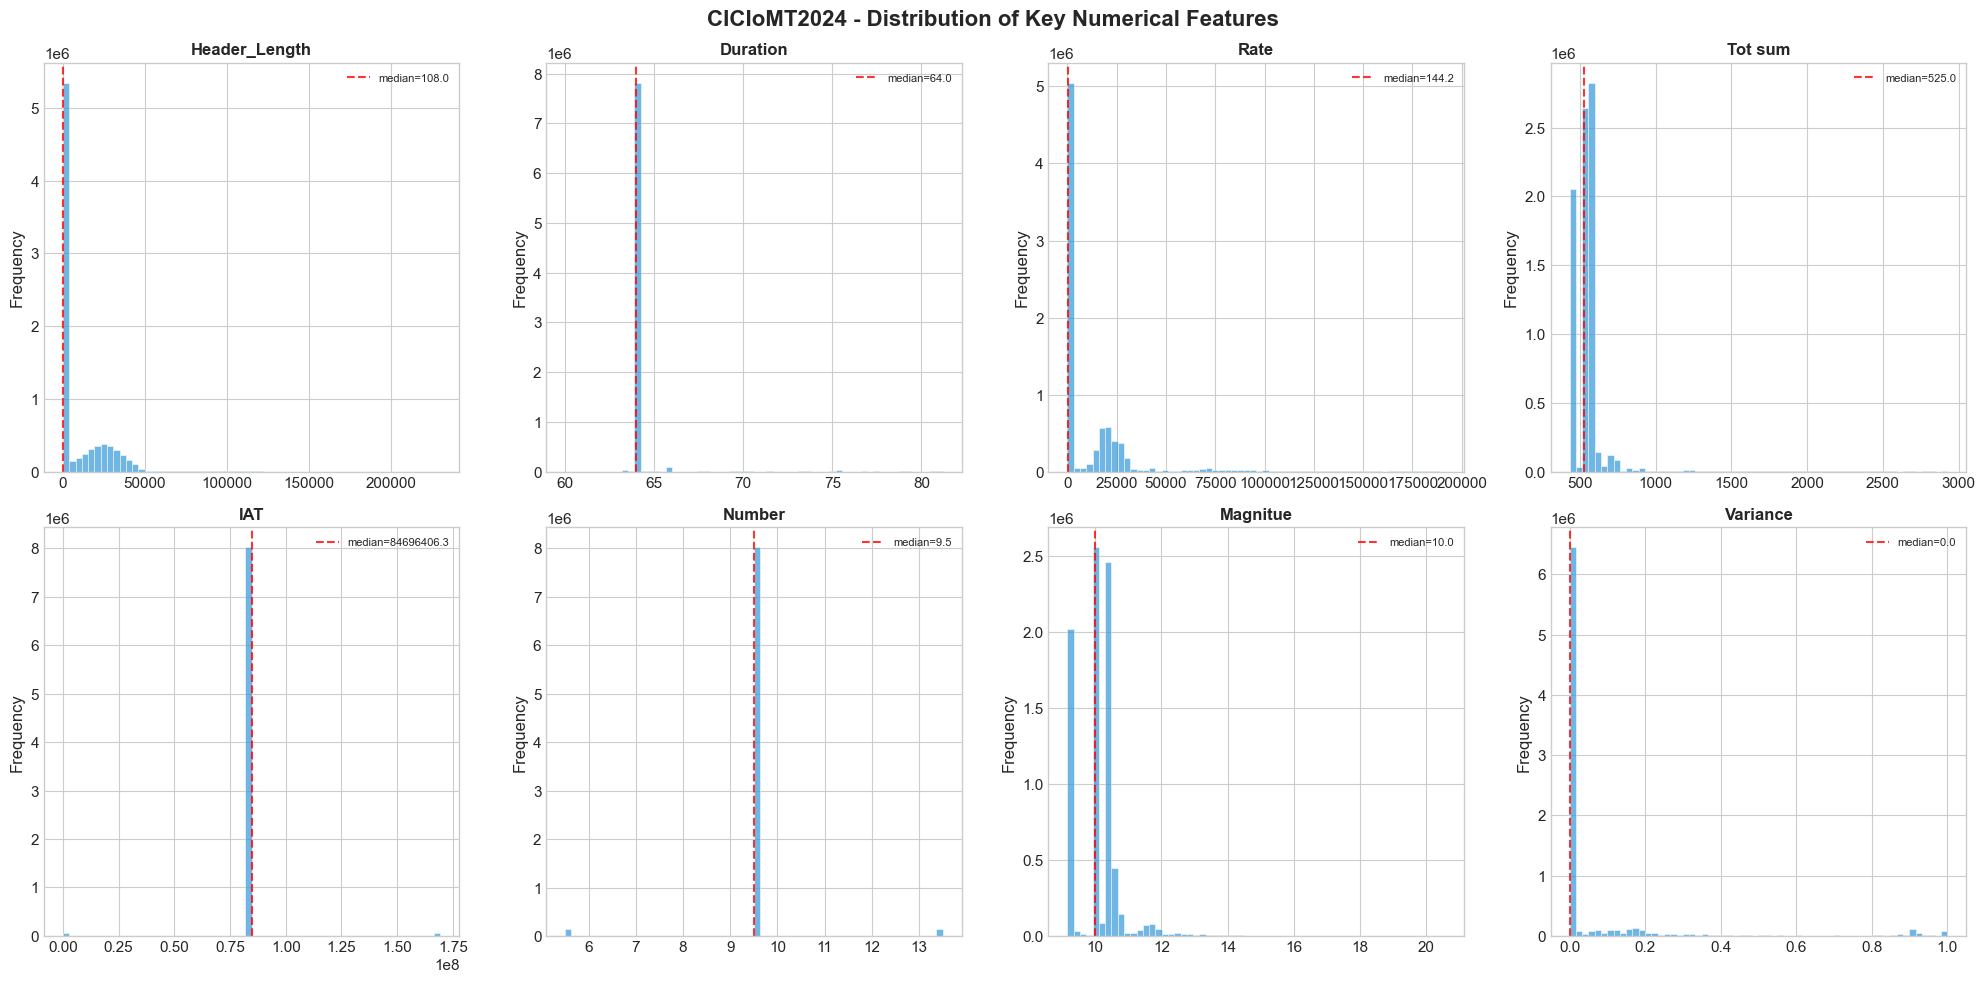

In [9]:
# ── Feature Distributions: Key numerical features ──
key_features = ['Header_Length', 'Duration', 'Rate', 'Tot sum', 'IAT', 'Number', 'Magnitue', 'Variance']

fig, axes = plt.subplots(2, 4, figsize=(20, 10))
fig.suptitle('CICIoMT2024 - Distribution of Key Numerical Features', fontsize=16, fontweight='bold')

for ax, feat in zip(axes.ravel(), key_features):
    data = df[feat].replace([np.inf, -np.inf], np.nan).dropna()
    # Clip extreme outliers for better visualization
    q_low, q_high = data.quantile(0.01), data.quantile(0.99)
    data_clipped = data[(data >= q_low) & (data <= q_high)]
    
    ax.hist(data_clipped, bins=60, color='#3498db', alpha=0.7, edgecolor='white', linewidth=0.5)
    ax.set_title(feat, fontsize=12, fontweight='bold')
    ax.set_ylabel('Frequency')
    ax.ticklabel_format(style='scientific', axis='y', scilimits=(0, 0))
    # Add stats
    ax.axvline(data.median(), color='red', linestyle='--', alpha=0.8, label=f'median={data.median():.1f}')
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

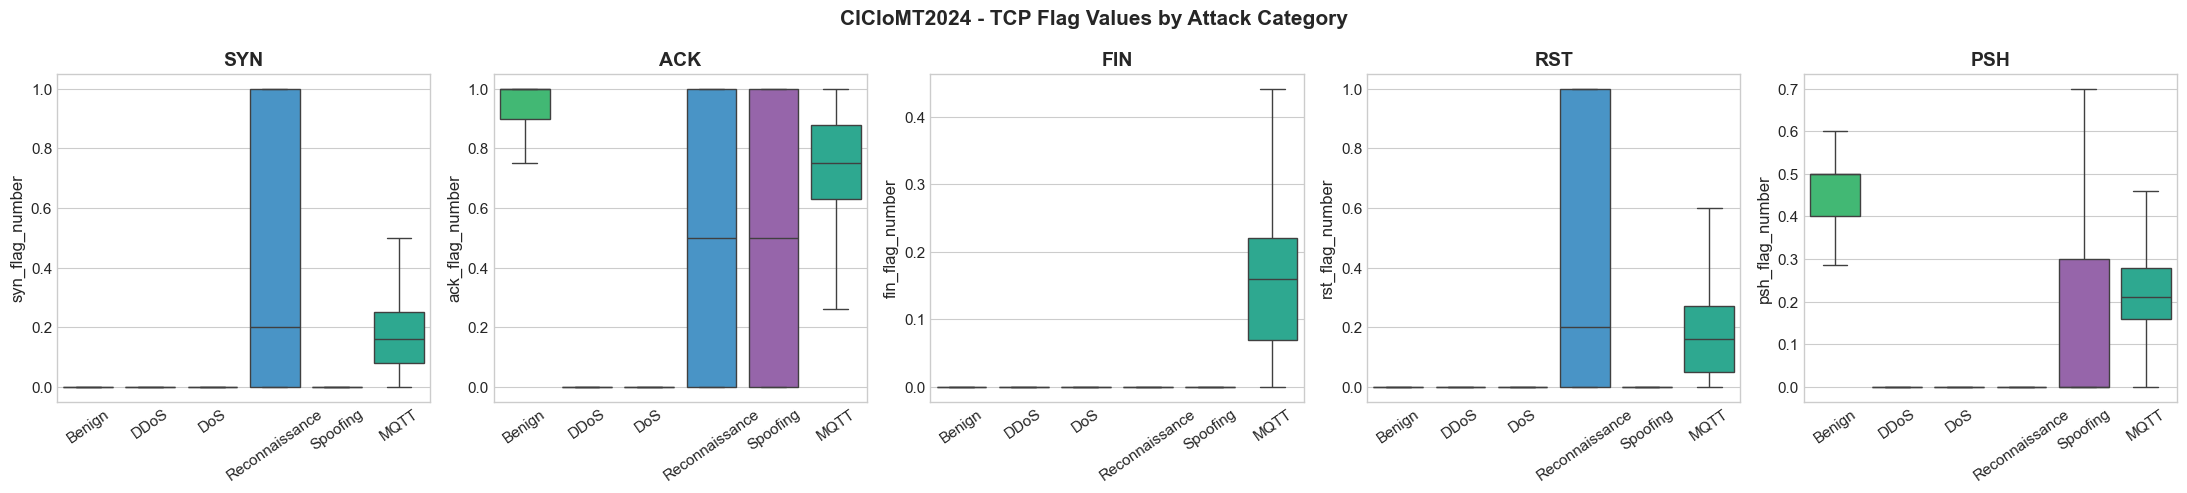

In [10]:
# ── TCP Flag Distributions per Attack Category ──
# First, define attack category mapping
def get_attack_category(label: str) -> str:
    """Map fine-grained label to coarse attack category.
    
    According to the CICIoMT2024 paper (Dadkhah et al., 2024), the 5 attack
    categories are defined by the protocol/topology targeted:
      - DDoS: only TCP/IP-based DDoS floods
      - DoS:  only TCP/IP-based DoS floods
      - MQTT: ALL MQTT-protocol attacks (DDoS, DoS, and Malformed)
      - Recon: Reconnaissance attacks (OS/Port/Vuln Scan, Ping Sweep)
      - Spoofing: ARP Spoofing
    """
    if label == 'Benign':
        return 'Benign'
    elif label.startswith('MQTT'):
        # ALL MQTT attacks belong to the MQTT category (paper Table 6)
        return 'MQTT'
    elif label.startswith('TCP_IP-DDoS'):
        return 'DDoS'
    elif label.startswith('TCP_IP-DoS'):
        return 'DoS'
    elif label.startswith('Recon'):
        return 'Reconnaissance'
    elif label == 'ARP_Spoofing':
        return 'Spoofing'
    else:
        return 'Other'

df['attack_category'] = df['label'].apply(get_attack_category)

# TCP flags boxplots by attack category
tcp_flags = ['syn_flag_number', 'ack_flag_number', 'fin_flag_number',
             'rst_flag_number', 'psh_flag_number']

fig, axes = plt.subplots(1, 5, figsize=(22, 5))
fig.suptitle('CICIoMT2024 - TCP Flag Values by Attack Category', fontsize=15, fontweight='bold')

cat_order = ['Benign', 'DDoS', 'DoS', 'Reconnaissance', 'Spoofing', 'MQTT']

for ax, flag in zip(axes, tcp_flags):
    sns.boxplot(
        data=df, x='attack_category', y=flag, ax=ax,
        order=cat_order, palette=CATEGORY_COLORS, showfliers=False
    )
    ax.set_title(flag.replace('_flag_number', '').upper(), fontweight='bold')
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=35)

plt.tight_layout()
plt.show()

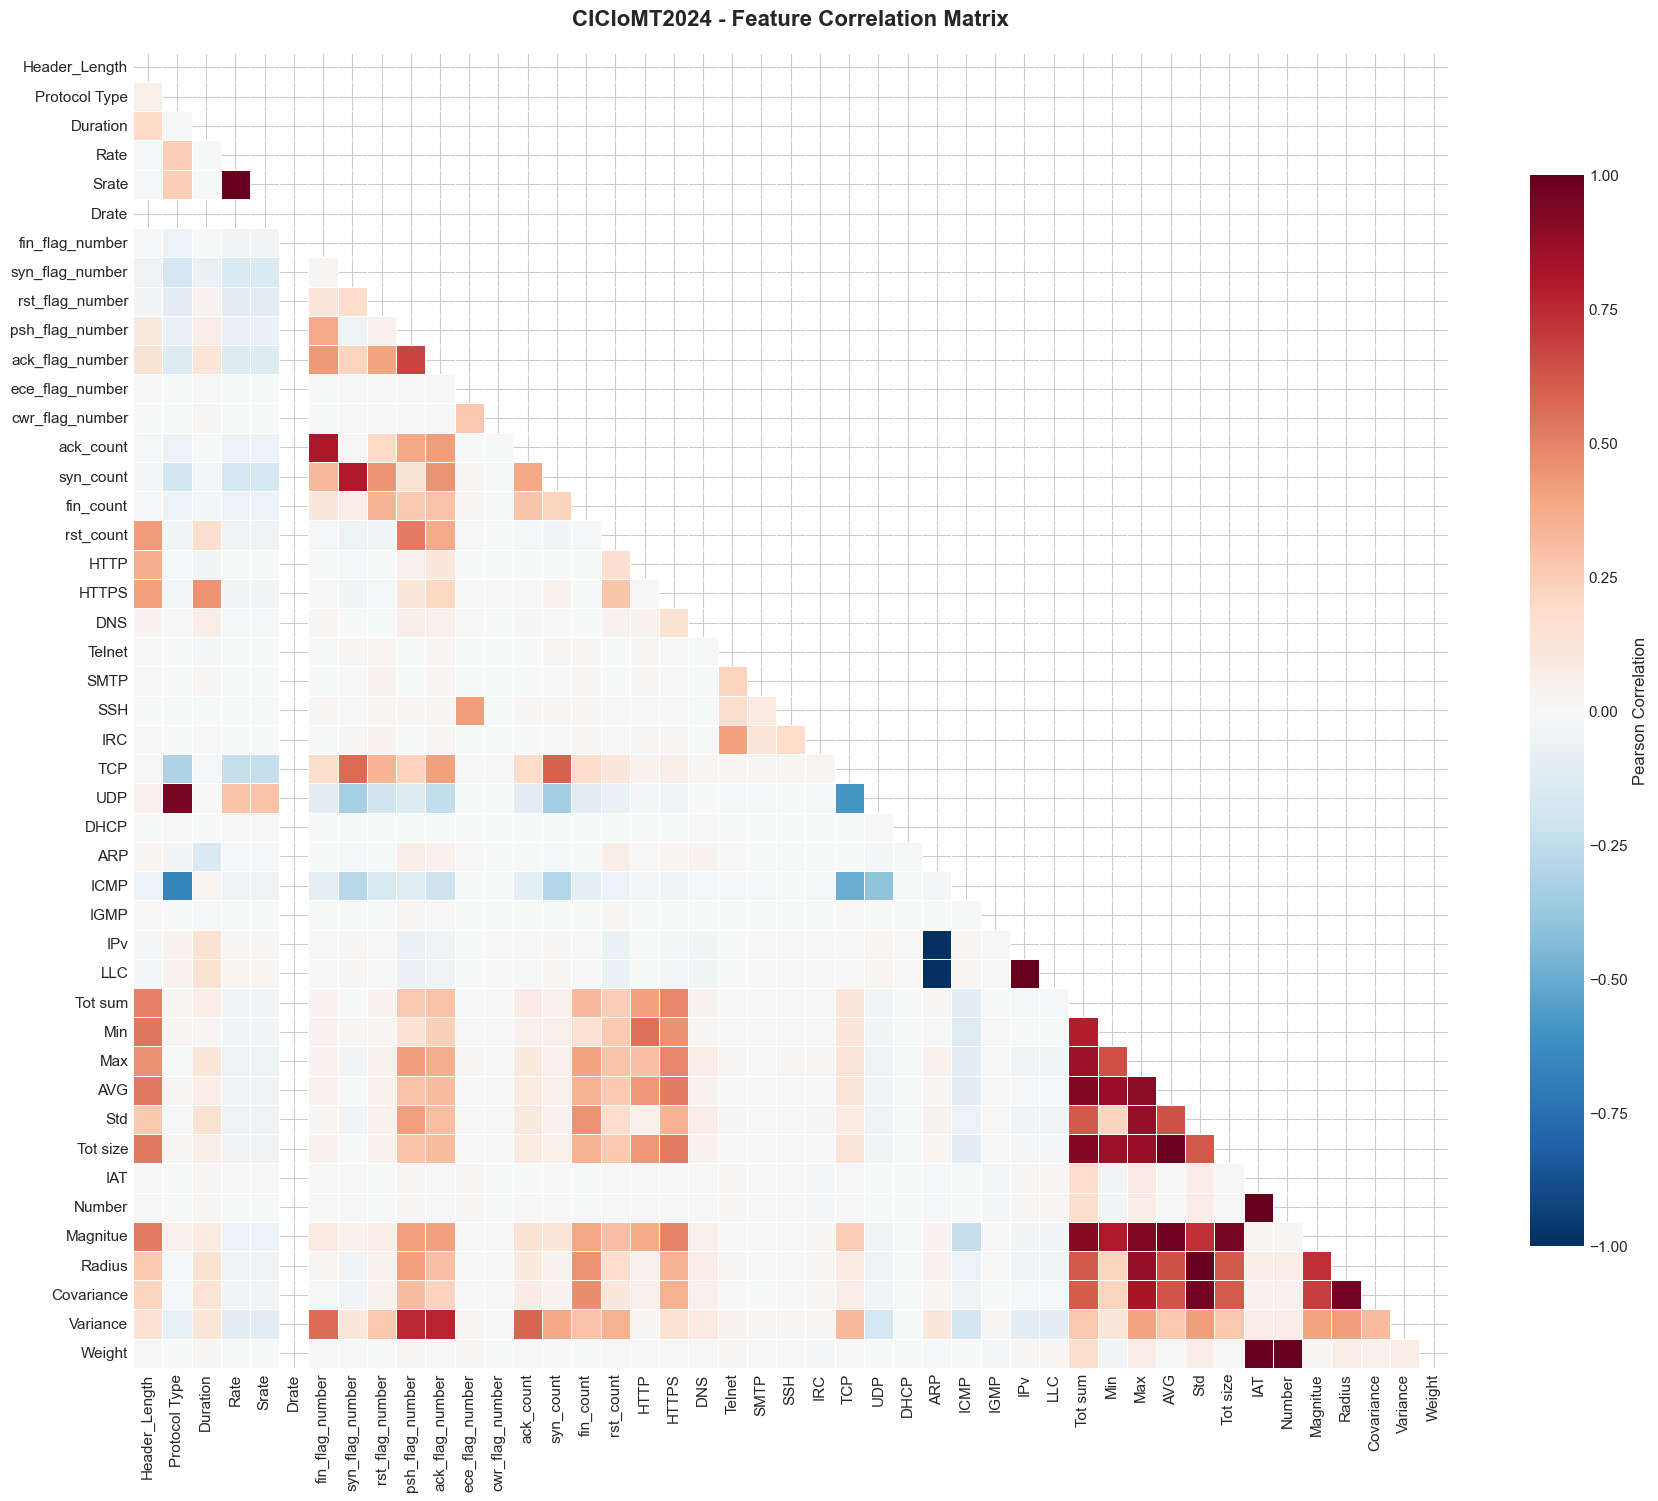


Highly Correlated Feature Pairs (|r| > 0.90):
  Rate                      <-> Srate                      r = +1.0000
  IPv                       <-> LLC                        r = +1.0000
  ARP                       <-> IPv                        r = -1.0000
  ARP                       <-> LLC                        r = -1.0000
  Std                       <-> Radius                     r = +1.0000
  Number                    <-> Weight                     r = +0.9997
  IAT                       <-> Weight                     r = +0.9991
  IAT                       <-> Number                     r = +0.9982
  AVG                       <-> Tot size                   r = +0.9816
  AVG                       <-> Magnitue                   r = +0.9743
  Radius                    <-> Covariance                 r = +0.9661
  Std                       <-> Covariance                 r = +0.9661
  Tot size                  <-> Magnitue                   r = +0.9559
  Protocol Type             <-

In [11]:
# ── Correlation Heatmap ──
numerical_features = df[FEATURE_COLS].select_dtypes(include=[np.number]).columns.tolist()

# Use a sample for large datasets
sample_size = min(200_000, len(df))
df_sample = df.sample(n=sample_size, random_state=42)

corr_matrix = df_sample[numerical_features].corr()

fig, ax = plt.subplots(figsize=(18, 15))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix, mask=mask, cmap='RdBu_r', center=0,
    vmin=-1, vmax=1, annot=False,
    square=True, linewidths=0.5,
    cbar_kws={'label': 'Pearson Correlation', 'shrink': 0.8},
    ax=ax
)
ax.set_title('CICIoMT2024 - Feature Correlation Matrix', fontsize=16, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

# ── Highly correlated feature pairs ──
print('\nHighly Correlated Feature Pairs (|r| > 0.90):')
print('=' * 60)
high_corr_pairs = []
for i in range(len(corr_matrix.columns)):
    for j in range(i + 1, len(corr_matrix.columns)):
        r = corr_matrix.iloc[i, j]
        if abs(r) > 0.90:
            high_corr_pairs.append((
                corr_matrix.columns[i],
                corr_matrix.columns[j],
                r
            ))

high_corr_pairs.sort(key=lambda x: abs(x[2]), reverse=True)
for f1, f2, r in high_corr_pairs:
    print(f'  {f1:25s} <-> {f2:25s}  r = {r:+.4f}')

print(f'\nTotal pairs with |r| > 0.90: {len(high_corr_pairs)}')

## 6. Label Analysis & Attack Taxonomy

Analysis of label distribution across three classification levels (paper Section 5):
- **Binary** (2 classes): Benign vs Attack
- **Categorical** (6 classes): Benign, DDoS, DoS, Recon, MQTT, Spoofing -- according to paper Table 6
- **Multiclass / Fine-grained** (19 classes): All 18 attack types + Benign

> **Important**: In categorical classification, MQTT-DDoS and MQTT-DoS belong to the **MQTT** category (based on protocol), NOT to DDoS/DoS (which refer only to TCP/IP).

In [12]:
# ── Fine-grained label distribution ──
label_counts = df['label'].value_counts()

print('Fine-Grained Label Distribution (19 classes)')
print('=' * 70)
for label, count in label_counts.items():
    pct = count / len(df) * 100
    bar = '█' * int(pct * 2)
    print(f'  {label:35s} {count:>10,}  ({pct:5.2f}%)  {bar}')

print(f'\nTotal classes: {df["label"].nunique()}')
print(f'Most frequent:  {label_counts.index[0]} ({label_counts.iloc[0]:,})')
print(f'Least frequent: {label_counts.index[-1]} ({label_counts.iloc[-1]:,})')
print(f'Imbalance ratio (max/min): {label_counts.iloc[0] / label_counts.iloc[-1]:.1f}x')

Fine-Grained Label Distribution (19 classes)
  TCP_IP-DDoS-UDP                      1,998,026  (24.01%)  ████████████████████████████████████████████████
  TCP_IP-DDoS-ICMP                     1,586,964  (19.07%)  ██████████████████████████████████████
  TCP_IP-DDoS-TCP                        987,063  (11.86%)  ███████████████████████
  TCP_IP-DDoS-SYN                        974,359  (11.71%)  ███████████████████████
  TCP_IP-DoS-UDP                         704,503  ( 8.46%)  ████████████████
  TCP_IP-DoS-SYN                         540,498  ( 6.49%)  ████████████
  TCP_IP-DoS-ICMP                        514,724  ( 6.18%)  ████████████
  TCP_IP-DoS-TCP                         462,480  ( 5.56%)  ███████████
  MQTT-DDoS-Connect_Flood                205,495  ( 2.47%)  ████
  Benign                                 133,197  ( 1.60%)  ███
  Recon-Port_Scan                        106,603  ( 1.28%)  ██
  MQTT-DDoS-Publish_Flood                 36,039  ( 0.43%)  
  Recon-OS_Scan                


Total classes: 19
Most frequent:  TCP_IP-DDoS-UDP (1,998,026)
Least frequent: Recon-Ping_Sweep (926)
Imbalance ratio (max/min): 2157.7x


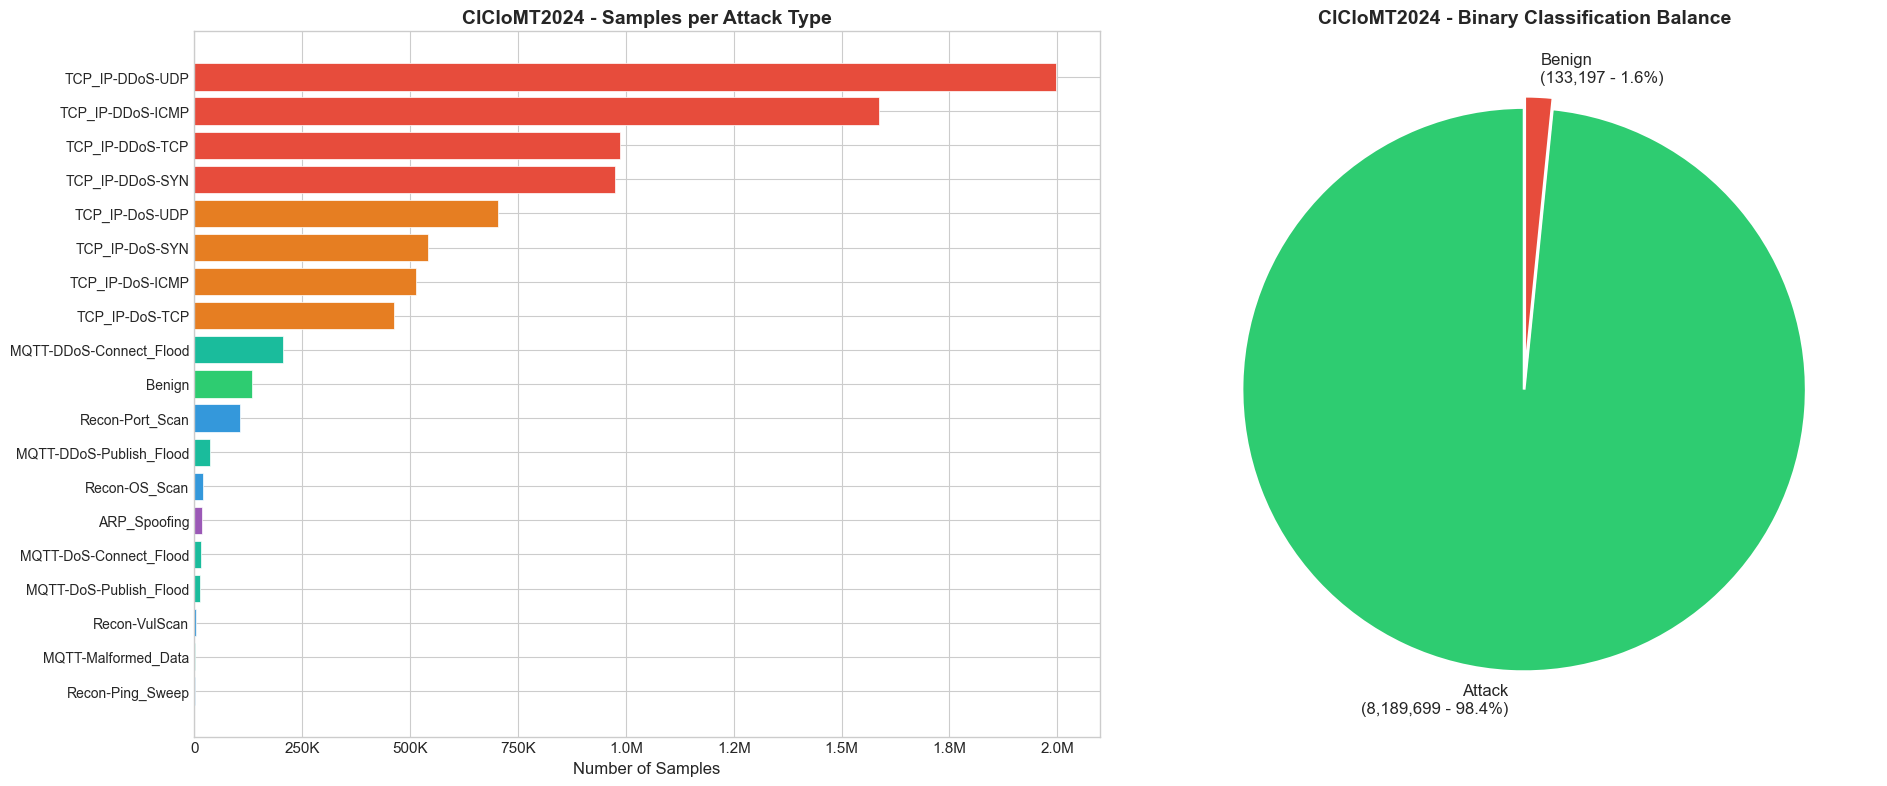

In [13]:
# ── Visualization: Label Distribution ──
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

# Bar chart - Fine-grained labels
colors = [CATEGORY_COLORS.get(get_attack_category(l), '#95a5a6') for l in label_counts.index]
ax = axes[0]
bars = ax.barh(range(len(label_counts)), label_counts.values, color=colors, edgecolor='white', linewidth=0.5)
ax.set_yticks(range(len(label_counts)))
ax.set_yticklabels(label_counts.index, fontsize=10)
ax.set_xlabel('Number of Samples')
ax.set_title('CICIoMT2024 - Samples per Attack Type', fontweight='bold')
ax.invert_yaxis()
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x/1e6:.1f}M' if x >= 1e6 else f'{x/1e3:.0f}K' if x >= 1e3 else f'{x:.0f}'))

# Pie chart - Binary classification
ax = axes[1]
binary_counts = df['label'].apply(lambda x: 'Benign' if x == 'Benign' else 'Attack').value_counts()
ax.pie(
    binary_counts.values,
    labels=[f'{l}\n({c:,} - {c/len(df)*100:.1f}%)' for l, c in binary_counts.items()],
    colors=['#2ecc71', '#e74c3c'],
    autopct='',
    startangle=90,
    explode=[0.02, 0.02],
    textprops={'fontsize': 12},
    wedgeprops={'edgecolor': 'white', 'linewidth': 2},
)
ax.set_title('CICIoMT2024 - Binary Classification Balance', fontweight='bold')

plt.tight_layout()
plt.show()

Attack Category Distribution (6 classes)
  DDoS                  5,546,412  (66.64%)
  DoS                   2,222,205  (26.70%)
  MQTT                    271,889  ( 3.27%)
  Benign                  133,197  ( 1.60%)
  Reconnaissance          131,402  ( 1.58%)
  Spoofing                 17,791  ( 0.21%)


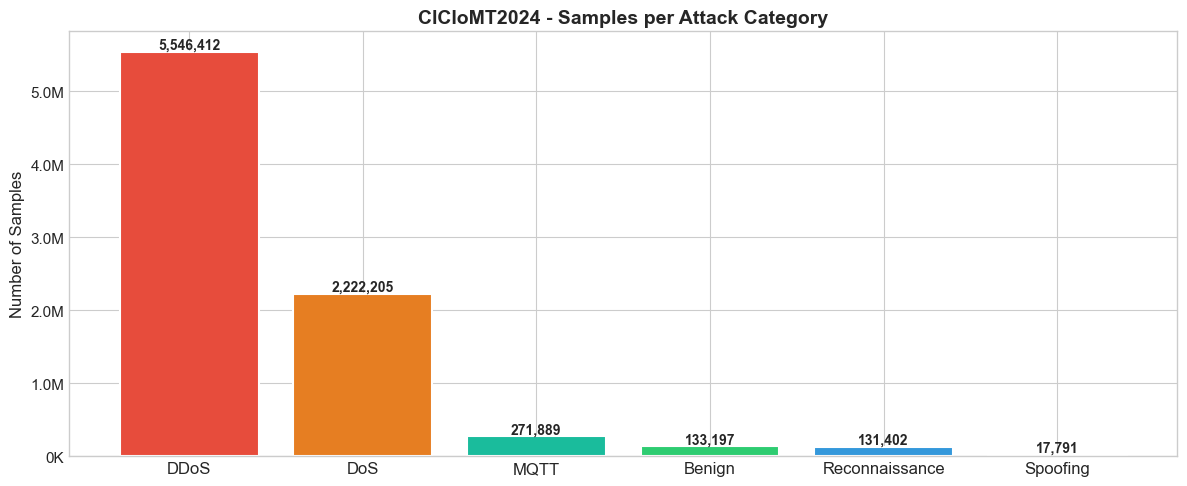

In [14]:
# ── Attack Category Distribution ──
cat_counts = df['attack_category'].value_counts()

print('Attack Category Distribution (6 classes)')
print('=' * 60)
for cat, count in cat_counts.items():
    pct = count / len(df) * 100
    print(f'  {cat:20s} {count:>10,}  ({pct:5.2f}%)')

# Category bar plot
fig, ax = plt.subplots(figsize=(12, 5))
cat_order_sorted = cat_counts.index.tolist()
colors_sorted = [CATEGORY_COLORS.get(c, '#95a5a6') for c in cat_order_sorted]

bars = ax.bar(range(len(cat_counts)), cat_counts.values, color=colors_sorted, edgecolor='white', linewidth=1.5)
ax.set_xticks(range(len(cat_counts)))
ax.set_xticklabels(cat_order_sorted, fontsize=12)
ax.set_ylabel('Number of Samples')
ax.set_title('CICIoMT2024 - Samples per Attack Category', fontsize=14, fontweight='bold')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x/1e6:.1f}M' if x >= 1e6 else f'{x/1e3:.0f}K'))

# Add value labels
for bar, count in zip(bars, cat_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
            f'{count:,}', ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

In [15]:
# ── Label Hierarchy Table ──
# Create a comprehensive mapping table for all classification levels

label_hierarchy = []
for label in sorted(df['label'].unique()):
    category = get_attack_category(label)
    binary = 'Benign' if label == 'Benign' else 'Attack'
    count = (df['label'] == label).sum()
    
    # Determine protocol vector
    if 'MQTT' in label:
        protocol = 'MQTT'
    elif 'TCP' in label or 'SYN' in label:
        protocol = 'TCP'
    elif 'UDP' in label:
        protocol = 'UDP'
    elif 'ICMP' in label:
        protocol = 'ICMP'
    elif 'ARP' in label:
        protocol = 'ARP'
    elif label == 'Benign':
        protocol = 'Mixed'
    elif 'Recon' in label:
        protocol = 'TCP/ICMP'
    else:
        protocol = 'Unknown'
    
    label_hierarchy.append({
        'Binary': binary,
        'Category': category,
        'Fine-Grained Label': label,
        'Attack Protocol': protocol,
        'Samples': count,
    })

df_hierarchy = pd.DataFrame(label_hierarchy)
print('Complete Label Hierarchy')
print('=' * 90)
print(df_hierarchy.to_string(index=False))

Complete Label Hierarchy
Binary       Category      Fine-Grained Label Attack Protocol  Samples
Attack       Spoofing            ARP_Spoofing             ARP    17791
Benign         Benign                  Benign           Mixed   133197
Attack           MQTT MQTT-DDoS-Connect_Flood            MQTT   205495
Attack           MQTT MQTT-DDoS-Publish_Flood            MQTT    36039
Attack           MQTT  MQTT-DoS-Connect_Flood            MQTT    15904
Attack           MQTT  MQTT-DoS-Publish_Flood            MQTT    12341
Attack           MQTT     MQTT-Malformed_Data            MQTT     2110
Attack Reconnaissance           Recon-OS_Scan        TCP/ICMP    20666
Attack Reconnaissance        Recon-Ping_Sweep        TCP/ICMP      926
Attack Reconnaissance         Recon-Port_Scan        TCP/ICMP   106603
Attack Reconnaissance           Recon-VulScan        TCP/ICMP     3207
Attack           DDoS        TCP_IP-DDoS-ICMP             TCP  1586964
Attack           DDoS         TCP_IP-DDoS-SYN       

In [16]:
# ── Cross-reference with Paper Table 6 ──
# Official counts from Dadkhah et al. (2024), Table 6
paper_counts = {
    'Benign': 230_339,
    'ARP_Spoofing': 17_791,
    'Recon-Ping_Sweep': 926,
    'Recon-VulScan': 3_207,
    'Recon-OS_Scan': 20_666,
    'Recon-Port_Scan': 106_603,
    'MQTT-Malformed_Data': 6_877,
    'MQTT-DoS-Connect_Flood': 15_904,
    'MQTT-DDoS-Publish_Flood': 36_039,
    'MQTT-DoS-Publish_Flood': 52_881,
    'MQTT-DDoS-Connect_Flood': 214_952,
    'TCP_IP-DoS-TCP': 462_480,
    'TCP_IP-DoS-ICMP': 514_724,
    'TCP_IP-DoS-SYN': 540_498,
    'TCP_IP-DoS-UDP': 704_503,
    'TCP_IP-DDoS-SYN': 974_359,
    'TCP_IP-DDoS-TCP': 987_063,
    'TCP_IP-DDoS-ICMP': 1_887_175,
    'TCP_IP-DDoS-UDP': 1_998_026,
}

our_counts = df['label'].value_counts().to_dict()

print('Cross-Reference: Our Data vs Paper Table 6')
print('=' * 85)
print(f'{"Label":35s} {"Ours":>12s} {"Paper":>12s} {"Diff":>10s} {"Status":>8s}')
print('-' * 85)

total_ours = 0
total_paper = 0
mismatches = 0

for label in sorted(paper_counts.keys()):
    p_count = paper_counts[label]
    o_count = our_counts.get(label, 0)
    diff = o_count - p_count
    total_ours += o_count
    total_paper += p_count
    status = 'OK' if diff == 0 else 'PARTIAL'
    if diff != 0:
        mismatches += 1
    print(f'{label:35s} {o_count:>12,} {p_count:>12,} {diff:>+10,} {status:>8s}')

print('-' * 85)
print(f'{"TOTAL":35s} {total_ours:>12,} {total_paper:>12,} {total_ours - total_paper:>+10,}')
print(f'\nMatching labels: {len(paper_counts) - mismatches}/{len(paper_counts)}')
print(f'Missing samples: {total_paper - total_ours:,} ({(total_paper - total_ours)/total_paper*100:.1f}%)')
print(f'\nNote: Differences are expected -- our CSVs come from WiFi_and_MQTT/attacks/csv/')
print(f'      The paper totals include profiling data and possibly additional capture sessions.')

Cross-Reference: Our Data vs Paper Table 6
Label                                       Ours        Paper       Diff   Status
-------------------------------------------------------------------------------------
ARP_Spoofing                              17,791       17,791         +0       OK
Benign                                   133,197      230,339    -97,142  PARTIAL
MQTT-DDoS-Connect_Flood                  205,495      214,952     -9,457  PARTIAL
MQTT-DDoS-Publish_Flood                   36,039       36,039         +0       OK
MQTT-DoS-Connect_Flood                    15,904       15,904         +0       OK
MQTT-DoS-Publish_Flood                    12,341       52,881    -40,540  PARTIAL
MQTT-Malformed_Data                        2,110        6,877     -4,767  PARTIAL
Recon-OS_Scan                             20,666       20,666         +0       OK
Recon-Ping_Sweep                             926          926         +0       OK
Recon-Port_Scan                          106,603   

## 7. Protocol Analysis

Analysis of protocol indicator features (TCP, UDP, MQTT, ARP, ICMP etc.) per attack category.

Mean Protocol Indicator Values per Attack Category
                   HTTP   HTTPS     DNS  Telnet    SMTP     SSH     IRC     TCP     UDP    DHCP     ARP    ICMP    IGMP     IPv     LLC
attack_category                                                                                                                        
Benign           0.0395  0.0694  0.0040  0.0000  0.0000  0.0000  0.0000  0.8863  0.0936  0.0000  0.0198  0.0001  0.0002  0.9802  0.9802
DDoS             0.0000  0.0016  0.0000  0.0000  0.0000  0.0000  0.0000  0.3546  0.3594  0.0000  0.0001  0.2859  0.0000  0.9999  0.9999
DoS              0.0000  0.0038  0.0000  0.0000  0.0000  0.0000  0.0000  0.4535  0.3150  0.0000  0.0001  0.2314  0.0000  0.9999  0.9999
MQTT             0.0000  0.0047  0.0000  0.0000  0.0000  0.0000  0.0000  0.9997  0.0001  0.0000  0.0001  0.0000  0.0000  0.9999  0.9999
Reconnaissance   0.0006  0.0096  0.0006  0.0005  0.0005  0.0014  0.0005  0.9472  0.0452  0.0000  0.0067  0.0008  0.0000  0.9933  0.99

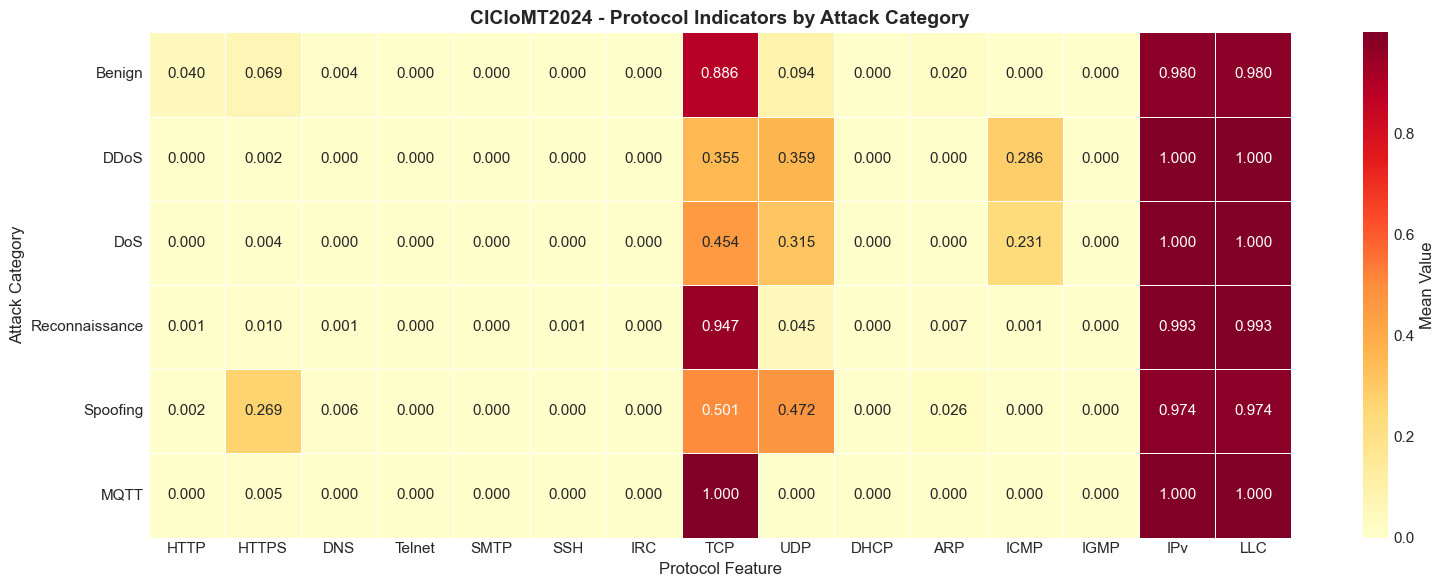

In [17]:
# ── Protocol indicator features ──
protocol_features = ['HTTP', 'HTTPS', 'DNS', 'Telnet', 'SMTP', 'SSH', 'IRC',
                     'TCP', 'UDP', 'DHCP', 'ARP', 'ICMP', 'IGMP', 'IPv', 'LLC']

# Mean values per attack category
proto_by_cat = df.groupby('attack_category')[protocol_features].mean()

print('Mean Protocol Indicator Values per Attack Category')
print('=' * 90)
print(proto_by_cat.round(4).to_string())

# Heatmap
fig, ax = plt.subplots(figsize=(16, 6))
ordered_cats = ['Benign', 'DDoS', 'DoS', 'Reconnaissance', 'Spoofing', 'MQTT']
proto_by_cat_ordered = proto_by_cat.reindex(ordered_cats)

sns.heatmap(
    proto_by_cat_ordered, annot=True, fmt='.3f', cmap='YlOrRd',
    linewidths=0.5, ax=ax, cbar_kws={'label': 'Mean Value'}
)
ax.set_title('CICIoMT2024 - Protocol Indicators by Attack Category', fontsize=14, fontweight='bold')
ax.set_ylabel('Attack Category')
ax.set_xlabel('Protocol Feature')
plt.tight_layout()
plt.show()

Dominant Transport Protocol per Attack Type
                            TCP     UDP     ARP    ICMP Dominant
label                                                           
ARP_Spoofing             0.5015  0.4721  0.0261  0.0004      TCP
Benign                   0.8863  0.0936  0.0198  0.0001      TCP
MQTT-DDoS-Connect_Flood  1.0000  0.0000  0.0000  0.0000      TCP
MQTT-DDoS-Publish_Flood  0.9997  0.0002  0.0001  0.0000      TCP
MQTT-DoS-Connect_Flood   0.9994  0.0003  0.0002  0.0000      TCP
MQTT-DoS-Publish_Flood   0.9998  0.0001  0.0001  0.0000      TCP
MQTT-Malformed_Data      0.9807  0.0095  0.0098  0.0000      TCP
Recon-OS_Scan            0.9838  0.0079  0.0044  0.0038      TCP
Recon-Ping_Sweep         0.2650  0.0120  0.7053  0.0177      ARP
Recon-Port_Scan          0.9520  0.0468  0.0012  0.0000      TCP
Recon-VulScan            0.7498  0.2427  0.0064  0.0009      TCP
TCP_IP-DDoS-ICMP         0.0023  0.0008  0.0001  0.9968     ICMP
TCP_IP-DDoS-SYN          0.9997  0.0002  0.000

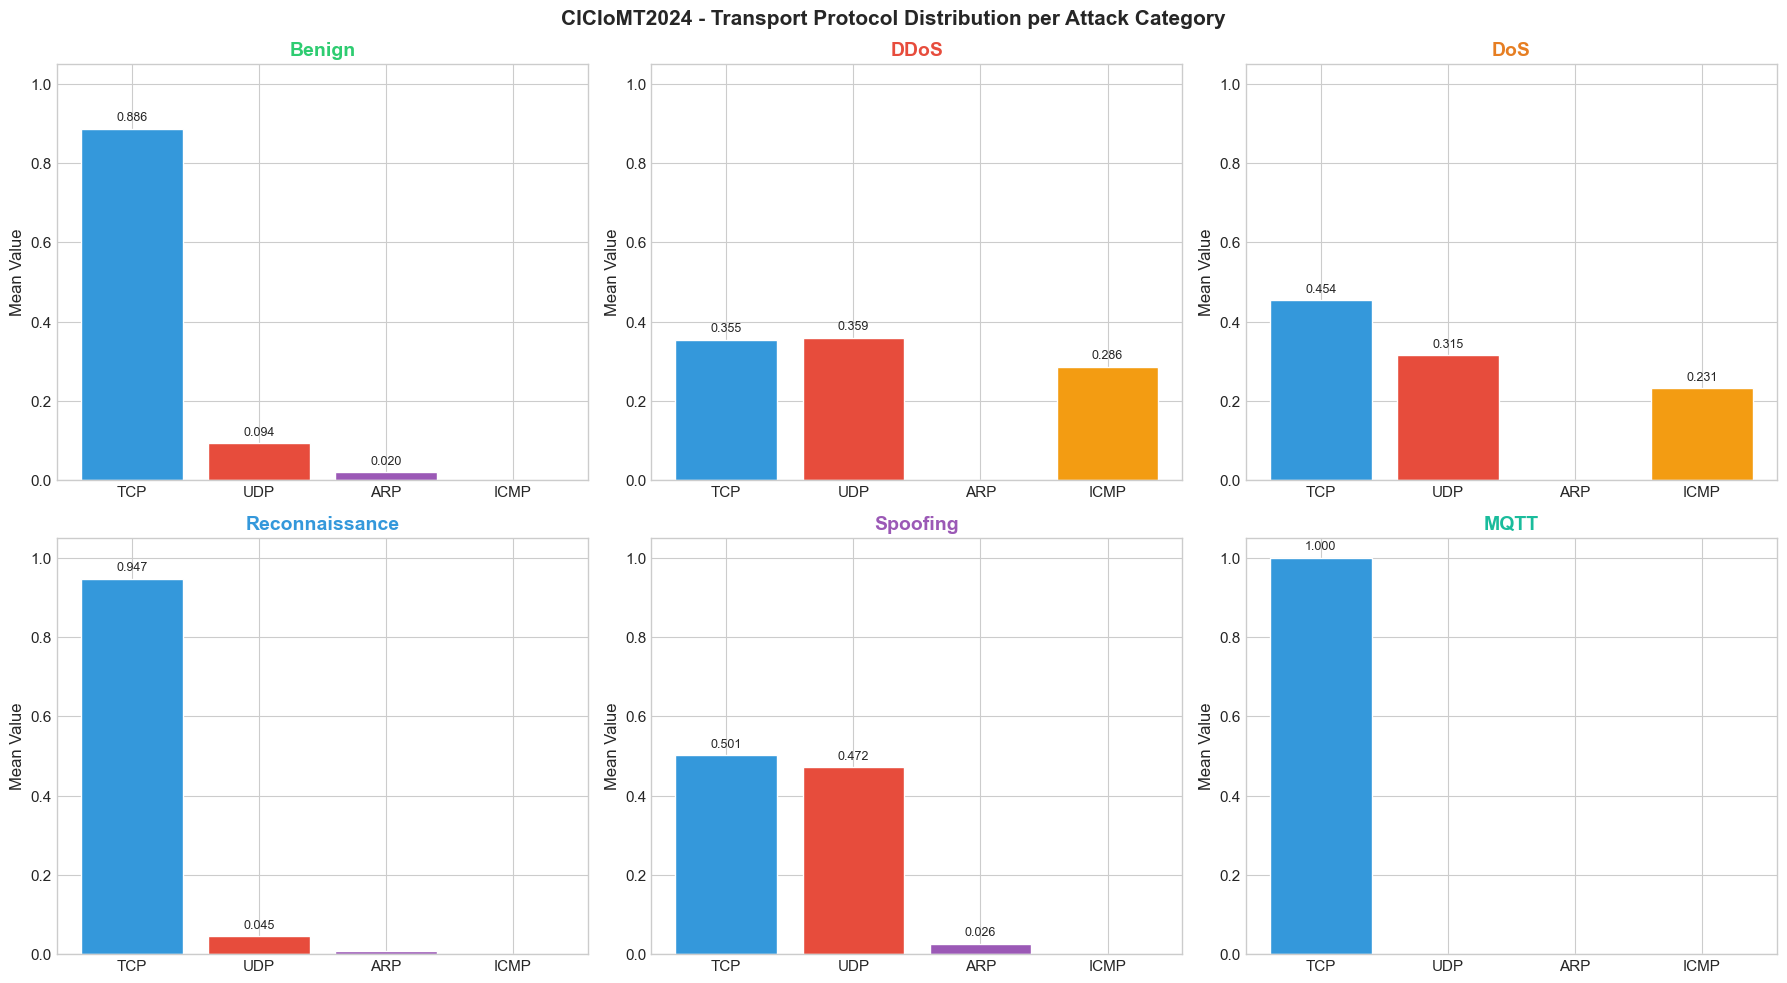

In [18]:
# ── Dominant protocol per attack type ──
# Determine which protocol has highest mean value per fine-grained label
transport_protos = ['TCP', 'UDP', 'ARP', 'ICMP']

proto_by_label = df.groupby('label')[transport_protos].mean()
proto_by_label['Dominant'] = proto_by_label.idxmax(axis=1)

print('Dominant Transport Protocol per Attack Type')
print('=' * 70)
print(proto_by_label.round(4).to_string())

# Protocol distribution per category
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('CICIoMT2024 - Transport Protocol Distribution per Attack Category',
             fontsize=15, fontweight='bold')

for ax, cat in zip(axes.ravel(), ordered_cats):
    cat_data = df[df['attack_category'] == cat][transport_protos].mean()
    colors = ['#3498db', '#e74c3c', '#9b59b6', '#f39c12']
    bars = ax.bar(cat_data.index, cat_data.values, color=colors, edgecolor='white')
    ax.set_title(cat, fontweight='bold', color=CATEGORY_COLORS.get(cat, '#333'))
    ax.set_ylim(0, 1.05)
    ax.set_ylabel('Mean Value')
    for bar, val in zip(bars, cat_data.values):
        if val > 0.01:
            ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
                    f'{val:.3f}', ha='center', fontsize=9)

plt.tight_layout()
plt.show()

## 8. Attack Category Deep Dive

Detailed analysis of each attack category: DDoS, DoS, Reconnaissance, Spoofing, MQTT.

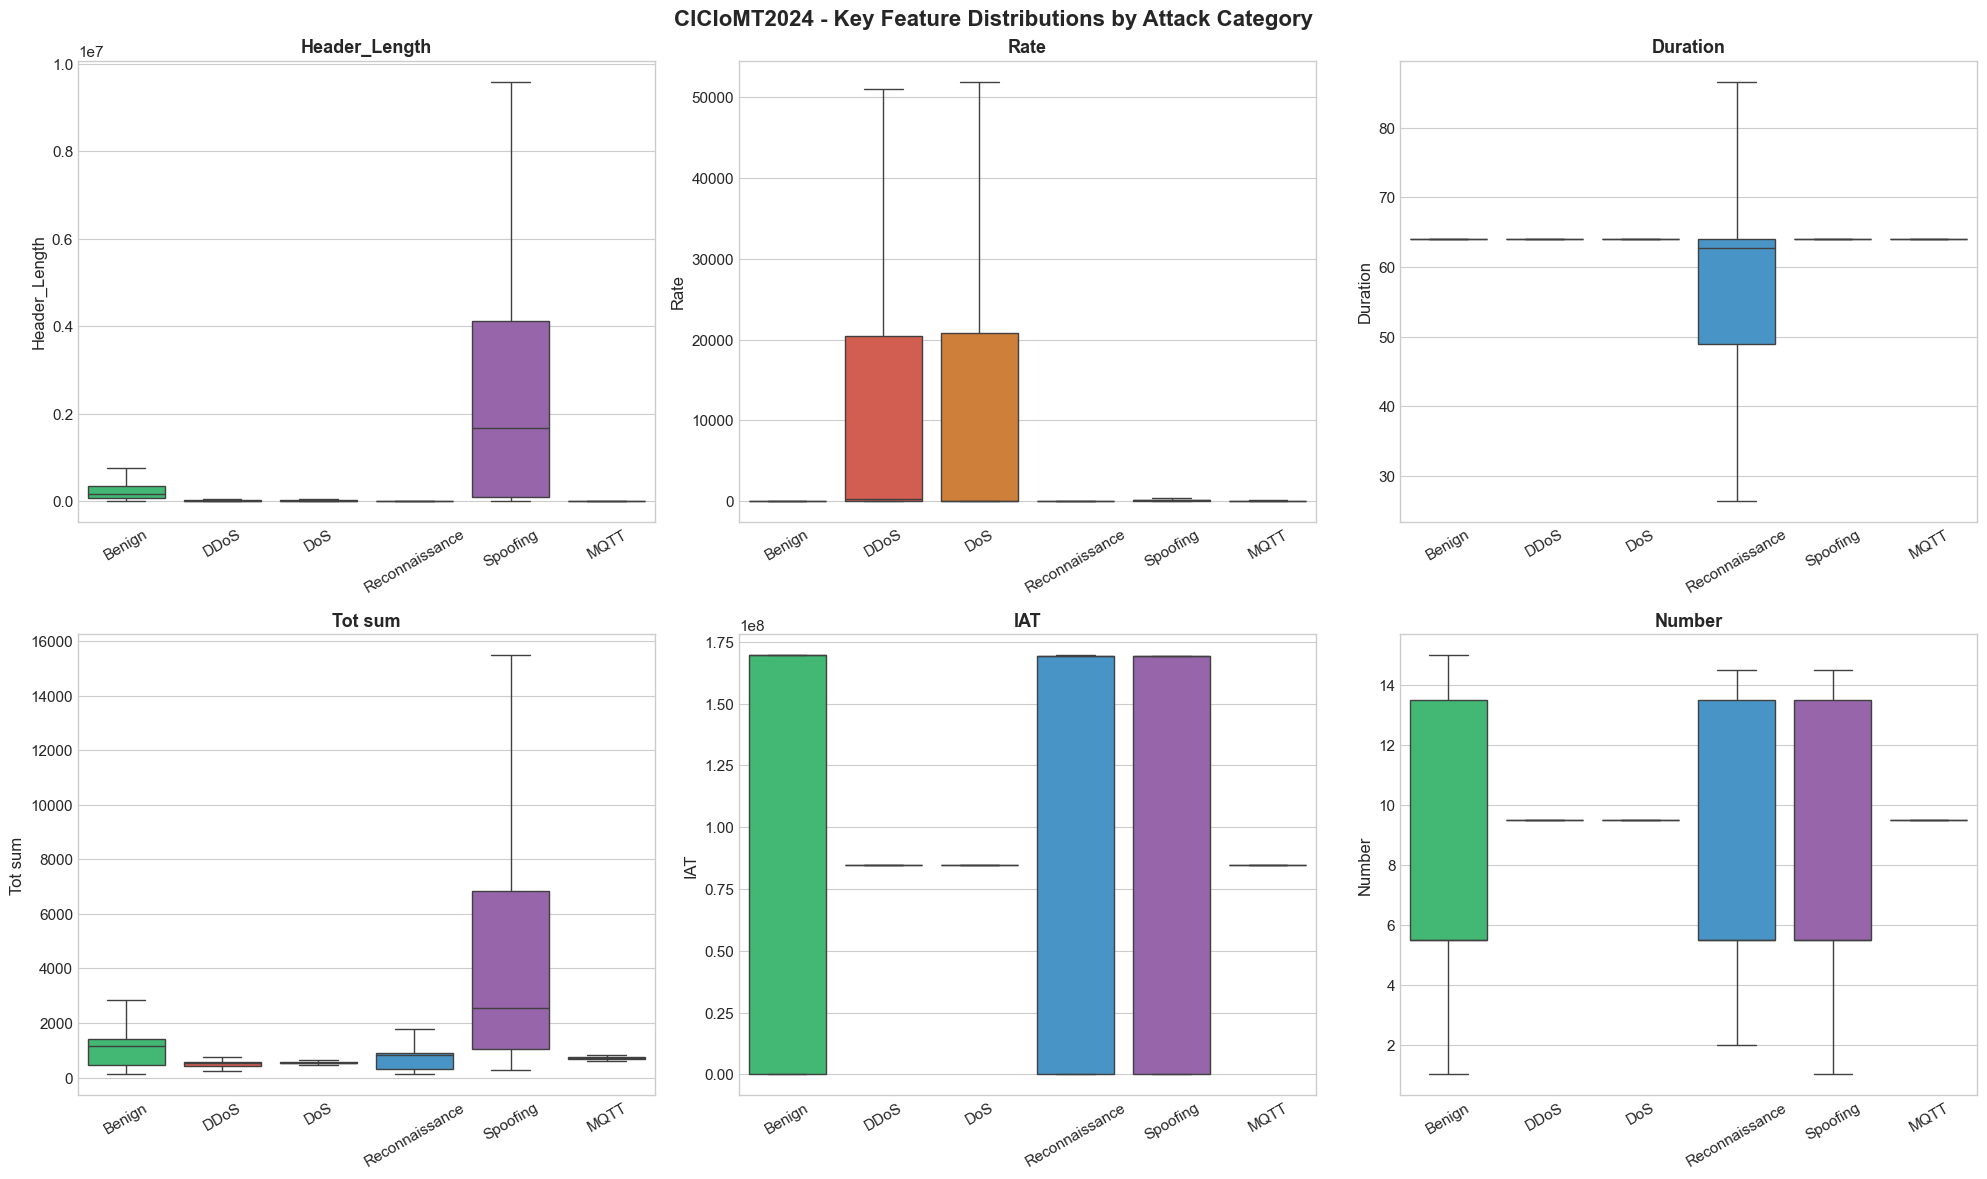

In [19]:
# ── Key features comparison across categories ──
comparison_features = ['Header_Length', 'Rate', 'Duration', 'Tot sum', 'IAT', 'Number']

fig, axes = plt.subplots(2, 3, figsize=(20, 12))
fig.suptitle('CICIoMT2024 - Key Feature Distributions by Attack Category',
             fontsize=16, fontweight='bold')

for ax, feat in zip(axes.ravel(), comparison_features):
    data_plot = df[[feat, 'attack_category']].copy()
    # Remove infinities for clean plotting
    data_plot[feat] = data_plot[feat].replace([np.inf, -np.inf], np.nan)
    
    sns.boxplot(
        data=data_plot, x='attack_category', y=feat,
        order=ordered_cats, palette=CATEGORY_COLORS,
        showfliers=False, ax=ax
    )
    ax.set_title(feat, fontsize=13, fontweight='bold')
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

In [20]:
# ── Per-category statistical summary ──
print('Statistical Summary per Attack Category')
print('=' * 80)

for cat in ordered_cats:
    cat_df = df[df['attack_category'] == cat]
    n_labels = cat_df['label'].nunique()
    labels = ', '.join(sorted(cat_df['label'].unique()))
    
    print(f'\n{cat} ({len(cat_df):,} samples, {n_labels} sub-types)')
    print(f'  Sub-types: {labels}')
    print(f'  Header_Length:  mean={cat_df["Header_Length"].mean():.2f}, std={cat_df["Header_Length"].std():.2f}')
    print(f'  Rate:           mean={cat_df["Rate"].mean():.2f}, std={cat_df["Rate"].std():.2f}')
    print(f'  Duration:       mean={cat_df["Duration"].mean():.2f}, std={cat_df["Duration"].std():.2f}')
    print(f'  Tot sum:        mean={cat_df["Tot sum"].mean():.2f}, std={cat_df["Tot sum"].std():.2f}')
    print(f'  IAT:            mean={cat_df["IAT"].mean():.2f}, std={cat_df["IAT"].std():.2f}')

Statistical Summary per Attack Category

Benign (133,197 samples, 1 sub-types)
  Sub-types: Benign
  Header_Length:  mean=447299.25, std=1080261.59
  Rate:           mean=316.26, std=2790.45
  Duration:       mean=68.89, std=22.54
  Tot sum:        mean=1964.85, std=3910.63
  IAT:            mean=84745783.38, std=84733377.43



DDoS (5,546,412 samples, 4 sub-types)
  Sub-types: TCP_IP-DDoS-ICMP, TCP_IP-DDoS-SYN, TCP_IP-DDoS-TCP, TCP_IP-DDoS-UDP
  Header_Length:  mean=10179.34, std=59394.20
  Rate:           mean=18270.45, std=43771.71
  Duration:       mean=64.32, std=2.42
  Tot sum:        mean=534.17, std=293.08
  IAT:            mean=84689522.95, std=1160642.97



DoS (2,222,205 samples, 4 sub-types)
  Sub-types: TCP_IP-DoS-ICMP, TCP_IP-DoS-SYN, TCP_IP-DoS-TCP, TCP_IP-DoS-UDP
  Header_Length:  mean=12187.33, std=87655.68
  Rate:           mean=12442.72, std=31760.91
  Duration:       mean=64.74, std=6.33
  Tot sum:        mean=570.37, std=495.09
  IAT:            mean=84664022.91, std=1347761.87



Reconnaissance (131,402 samples, 4 sub-types)
  Sub-types: Recon-OS_Scan, Recon-Ping_Sweep, Recon-Port_Scan, Recon-VulScan
  Header_Length:  mean=60855.81, std=293417.79
  Rate:           mean=155.70, std=3139.53
  Duration:       mean=62.27, std=25.87
  Tot sum:        mean=803.87, std=1096.92
  IAT:            mean=84710815.33, std=84705980.58

Spoofing (17,791 samples, 1 sub-types)
  Sub-types: ARP_Spoofing
  Header_Length:  mean=2456003.12, std=2491977.42
  Rate:           mean=375.04, std=3751.19
  Duration:       mean=81.17, std=50.69
  Tot sum:        mean=5021.47, std=6025.76
  IAT:            mean=84715495.60, std=84703592.20



MQTT (271,889 samples, 5 sub-types)
  Sub-types: MQTT-DDoS-Connect_Flood, MQTT-DDoS-Publish_Flood, MQTT-DoS-Connect_Flood, MQTT-DoS-Publish_Flood, MQTT-Malformed_Data
  Header_Length:  mean=15192.15, std=188318.67
  Rate:           mean=5565.71, std=35824.18
  Duration:       mean=64.30, std=5.92
  Tot sum:        mean=1458.04, std=2038.80
  IAT:            mean=84652354.54, std=7636286.69


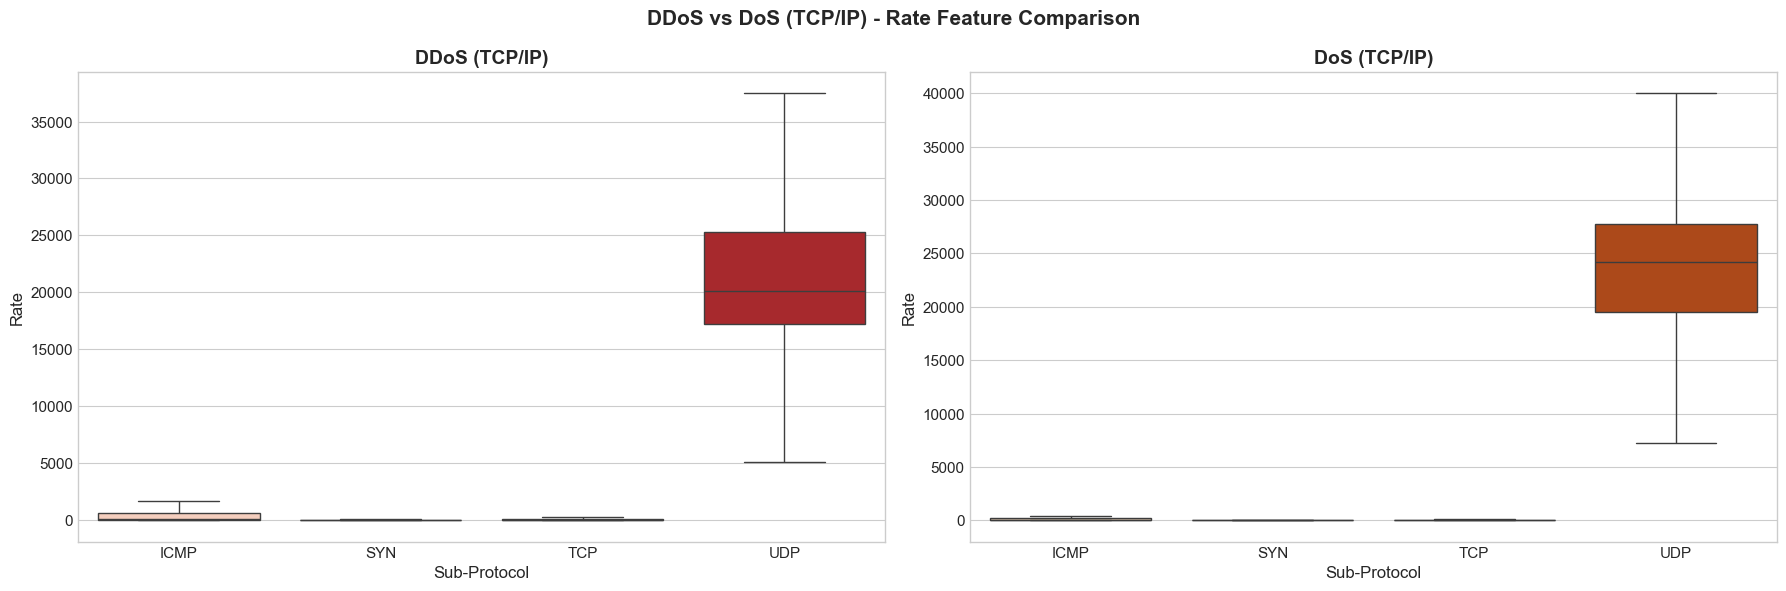


DDoS vs DoS - Mean Rate Comparison:
  DDoS overall mean Rate: 18,270.45
  DoS overall mean Rate:  12,442.72
  Ratio (DDoS/DoS):       1.47x


In [21]:
# ── DDoS vs DoS comparison ──
# These are the most prevalent categories -- compare TCP/IP variants

ddos_labels = [l for l in df['label'].unique() if 'DDoS' in l and l.startswith('TCP_IP')]
dos_labels = [l for l in df['label'].unique() if l.startswith('TCP_IP-DoS')]

df_ddos_tcpip = df[df['label'].isin(ddos_labels)].copy()
df_dos_tcpip = df[df['label'].isin(dos_labels)].copy()

# Extract sub-protocol (ICMP, SYN, TCP, UDP)
def extract_subprotocol(label):
    parts = label.split('-')
    return parts[-1] if parts else label

df_ddos_tcpip['sub_protocol'] = df_ddos_tcpip['label'].apply(extract_subprotocol)
df_dos_tcpip['sub_protocol'] = df_dos_tcpip['label'].apply(extract_subprotocol)

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
fig.suptitle('DDoS vs DoS (TCP/IP) - Rate Feature Comparison', fontsize=15, fontweight='bold')

# DDoS
sns.boxplot(data=df_ddos_tcpip, x='sub_protocol', y='Rate', showfliers=False,
            palette='Reds', ax=axes[0])
axes[0].set_title('DDoS (TCP/IP)', fontweight='bold')
axes[0].set_xlabel('Sub-Protocol')

# DoS
sns.boxplot(data=df_dos_tcpip, x='sub_protocol', y='Rate', showfliers=False,
            palette='Oranges', ax=axes[1])
axes[1].set_title('DoS (TCP/IP)', fontweight='bold')
axes[1].set_xlabel('Sub-Protocol')

plt.tight_layout()
plt.show()

# Print comparison
print('\nDDoS vs DoS - Mean Rate Comparison:')
print(f'  DDoS overall mean Rate: {df_ddos_tcpip["Rate"].mean():,.2f}')
print(f'  DoS overall mean Rate:  {df_dos_tcpip["Rate"].mean():,.2f}')
print(f'  Ratio (DDoS/DoS):       {df_ddos_tcpip["Rate"].mean() / max(df_dos_tcpip["Rate"].mean(), 1e-10):.2f}x')

## 9. MQTT-Specific Analysis

Analysis of MQTT-specific attacks, which are a unique characteristic of the CICIoMT2024 dataset compared to CICIoT2023.

According to the paper, **all** MQTT-related attacks (regardless of whether they are DDoS, DoS, or Malformed) belong to the same **"MQTT"** category (Table 6). This makes sense because the categorization is based on protocol/topology:

- **MQTT-DDoS-Connect_Flood**: Distributed flood of CONNECT packets (custom Python script)
- **MQTT-DDoS-Publish_Flood**: Distributed flood of PUBLISH messages
- **MQTT-DoS-Connect_Flood**: Single-source CONNECT flood
- **MQTT-DoS-Publish_Flood**: Single-source PUBLISH flood
- **MQTT-Malformed_Data**: Corrupted MQTT packets via MQTTSA tool (sniff broker + send malformed data)

The MQTT simulated devices run via **IoTFlock** (simulation platform) on VMware/Ubuntu, with a local MQTT broker.

In [22]:
# ── Filter MQTT attacks ──
mqtt_labels = [l for l in df['label'].unique() if 'MQTT' in l]
df_mqtt = df[df['label'].isin(mqtt_labels)].copy()

print('MQTT Attack Analysis')
print('=' * 60)
print(f'Total MQTT attack samples: {len(df_mqtt):,}')
print(f'Percentage of total dataset: {len(df_mqtt)/len(df)*100:.2f}%')
print()

for label in sorted(mqtt_labels):
    count = (df_mqtt['label'] == label).sum()
    pct = count / len(df_mqtt) * 100
    print(f'  {label:40s} {count:>8,}  ({pct:5.2f}%)')

# ── MQTT vs TCP/IP attacks comparison ──
print(f'\nMQTT vs TCP/IP Attack Comparison')
print('=' * 60)

mqtt_attacks = df[df['label'].str.startswith('MQTT')]
tcpip_attacks = df[df['label'].str.startswith('TCP_IP')]

for feat in ['Rate', 'Header_Length', 'Tot sum', 'Duration', 'IAT']:
    mqtt_mean = mqtt_attacks[feat].mean()
    tcpip_mean = tcpip_attacks[feat].mean()
    print(f'  {feat:20s}  MQTT: {mqtt_mean:>12.2f}  TCP/IP: {tcpip_mean:>12.2f}')

MQTT Attack Analysis
Total MQTT attack samples: 271,889
Percentage of total dataset: 3.27%

  MQTT-DDoS-Connect_Flood                   205,495  (75.58%)
  MQTT-DDoS-Publish_Flood                    36,039  (13.26%)
  MQTT-DoS-Connect_Flood                     15,904  ( 5.85%)
  MQTT-DoS-Publish_Flood                     12,341  ( 4.54%)
  MQTT-Malformed_Data                         2,110  ( 0.78%)

MQTT vs TCP/IP Attack Comparison


  Rate                  MQTT:      5565.71  TCP/IP:     16603.44
  Header_Length         MQTT:     15192.15  TCP/IP:     10753.72
  Tot sum               MQTT:      1458.04  TCP/IP:       544.52
  Duration              MQTT:        64.30  TCP/IP:        64.44
  IAT                   MQTT:  84652354.54  TCP/IP:  84682228.69


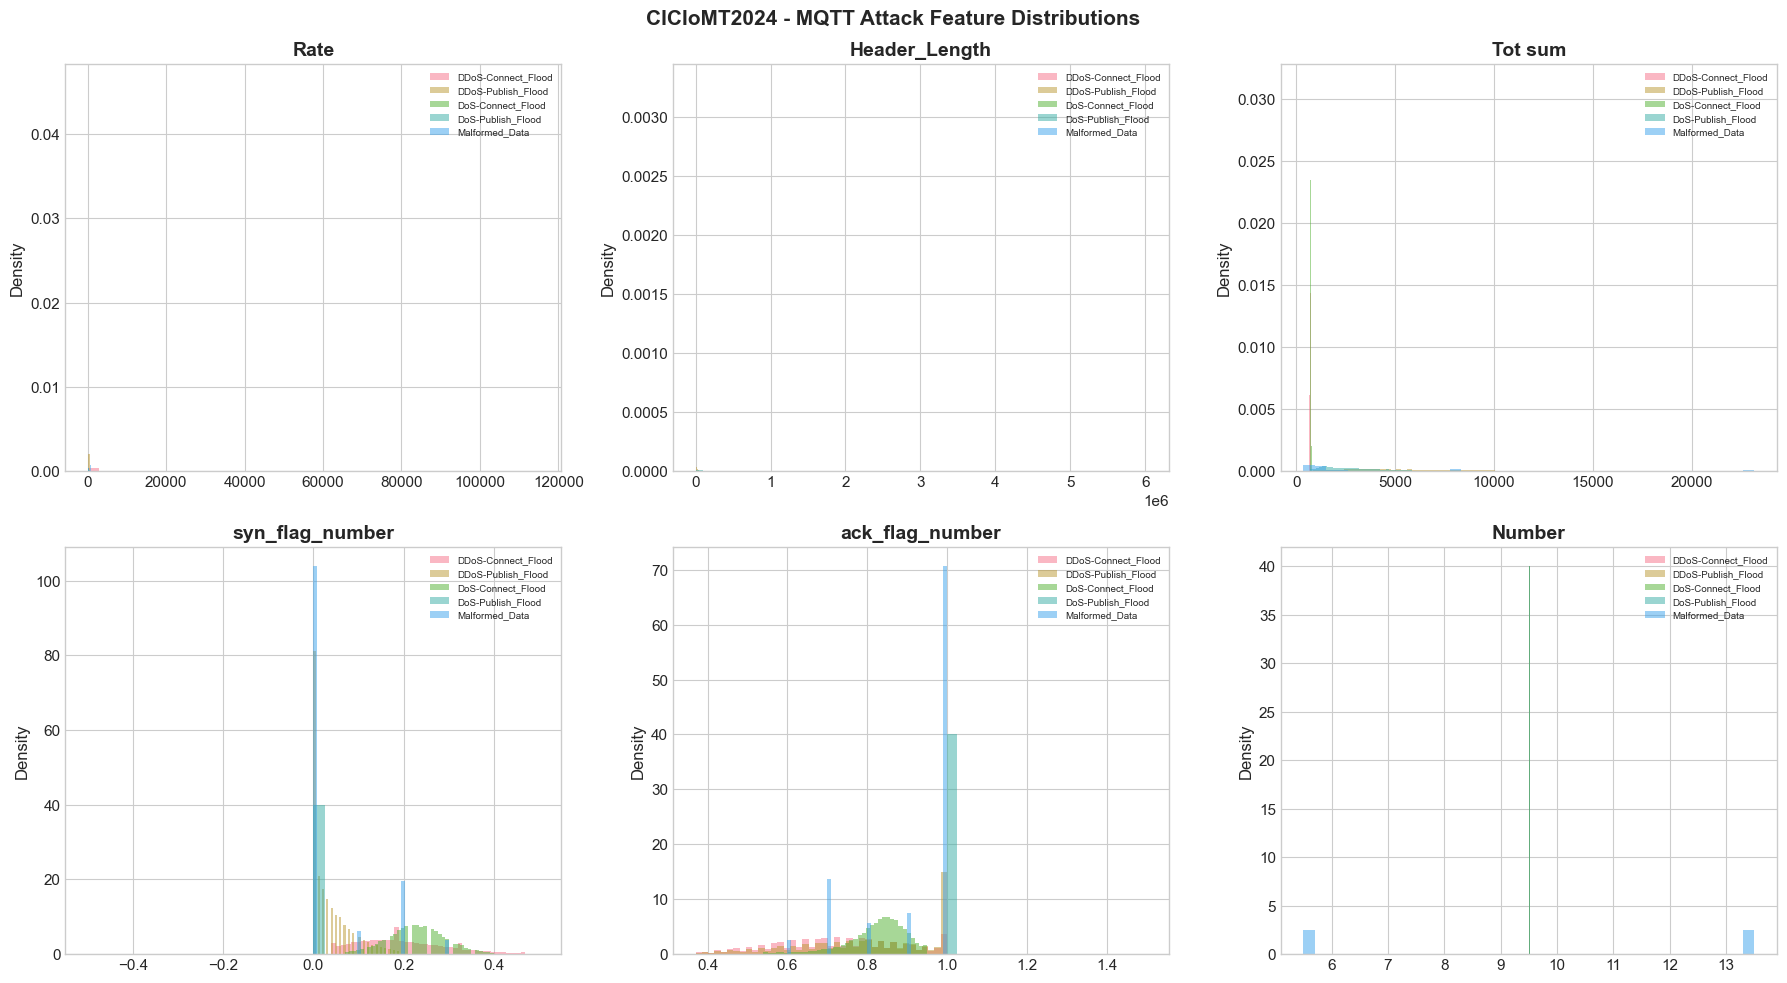

In [23]:
# ── MQTT attack feature distributions ──
mqtt_features = ['Rate', 'Header_Length', 'Tot sum', 'syn_flag_number', 'ack_flag_number', 'Number']

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('CICIoMT2024 - MQTT Attack Feature Distributions', fontsize=15, fontweight='bold')

for ax, feat in zip(axes.ravel(), mqtt_features):
    for label in sorted(mqtt_labels):
        data = df_mqtt[df_mqtt['label'] == label][feat]
        data = data.replace([np.inf, -np.inf], np.nan).dropna()
        q_low, q_high = data.quantile(0.02), data.quantile(0.98)
        data_clipped = data[(data >= q_low) & (data <= q_high)]
        # Simplify label for legend
        short_label = label.replace('MQTT-', '')
        ax.hist(data_clipped, bins=40, alpha=0.5, label=short_label, density=True)
    
    ax.set_title(feat, fontweight='bold')
    ax.legend(fontsize=7)
    ax.set_ylabel('Density')

plt.tight_layout()
plt.show()

In [24]:
# ── MQTT Malformed Data: Special case analysis ──
# This is the unique MQTT-specific attack (not DDoS/DoS variant)

df_malformed = df[df['label'] == 'MQTT-Malformed_Data']
df_benign = df[df['label'] == 'Benign']

print('MQTT Malformed Data vs Benign Traffic')
print('=' * 60)
print(f'MQTT-Malformed_Data samples: {len(df_malformed):,}')
print(f'Benign samples:              {len(df_benign):,}')
print()

compare_features = ['Header_Length', 'Rate', 'Duration', 'Tot sum', 'Variance', 'Magnitue']
print(f'{"Feature":25s} {"Malformed (mean)":>18s} {"Benign (mean)":>18s} {"Difference":>12s}')
print('-' * 75)
for feat in compare_features:
    mal_mean = df_malformed[feat].mean()
    ben_mean = df_benign[feat].mean()
    diff_pct = ((mal_mean - ben_mean) / max(abs(ben_mean), 1e-10)) * 100
    print(f'{feat:25s} {mal_mean:>18.4f} {ben_mean:>18.4f} {diff_pct:>+10.1f}%')

MQTT Malformed Data vs Benign Traffic
MQTT-Malformed_Data samples: 2,110
Benign samples:              133,197

Feature                     Malformed (mean)      Benign (mean)   Difference
---------------------------------------------------------------------------
Header_Length                   1181871.7082        447299.2484     +164.2%
Rate                                427.5073           316.2600      +35.2%
Duration                             95.3044            68.8905      +38.3%
Tot sum                            5334.6520          1964.8485     +171.5%
Variance                              0.6912             0.8738      -20.9%
Magnitue                             26.4064            16.4200      +60.8%


## 10. Train/Test Split Analysis

Comparison of train and test splits: label distribution, feature statistics.

In [25]:
# ── Train/Test size comparison ──
print('Train/Test Split Overview')
print('=' * 60)
print(f'Training samples:   {len(df_train):>10,}  ({len(df_train)/len(df)*100:.1f}%)')
print(f'Test samples:       {len(df_test):>10,}  ({len(df_test)/len(df)*100:.1f}%)')
print(f'Total samples:      {len(df):>10,}')
print(f'Train/Test ratio:   {len(df_train)/len(df_test):.2f}')

# ── Label distribution comparison ──
train_label_counts = df_train['label'].value_counts(normalize=True)
test_label_counts = df_test['label'].value_counts(normalize=True)

# Align on same labels
all_labels = sorted(df['label'].unique())
train_pcts = train_label_counts.reindex(all_labels, fill_value=0)
test_pcts = test_label_counts.reindex(all_labels, fill_value=0)

print(f'\nLabel Distribution Comparison (percentage)')
print('=' * 70)
print(f'{"Label":35s} {"Train %":>10s} {"Test %":>10s} {"Diff":>10s}')
print('-' * 70)
for label in all_labels:
    tr = train_pcts[label] * 100
    te = test_pcts[label] * 100
    diff = tr - te
    flag = ' ◄' if abs(diff) > 2.0 else ''
    print(f'{label:35s} {tr:>9.2f}% {te:>9.2f}% {diff:>+9.2f}%{flag}')

Train/Test Split Overview
Training samples:    6,708,714  (80.6%)
Test samples:        1,614,182  (19.4%)
Total samples:       8,322,896
Train/Test ratio:   4.16



Label Distribution Comparison (percentage)
Label                                  Train %     Test %       Diff
----------------------------------------------------------------------
ARP_Spoofing                             0.24%      0.11%     +0.13%
Benign                                   1.42%      2.33%     -0.90%
MQTT-DDoS-Connect_Flood                  2.44%      2.60%     -0.16%
MQTT-DDoS-Publish_Flood                  0.41%      0.52%     -0.11%
MQTT-DoS-Connect_Flood                   0.19%      0.19%     -0.00%
MQTT-DoS-Publish_Flood                   0.06%      0.53%     -0.47%
MQTT-Malformed_Data                      0.01%      0.11%     -0.10%
Recon-OS_Scan                            0.25%      0.24%     +0.01%
Recon-Ping_Sweep                         0.01%      0.01%     -0.00%
Recon-Port_Scan                          1.25%      1.40%     -0.15%
Recon-VulScan                            0.03%      0.06%     -0.03%
TCP_IP-DDoS-ICMP                        18.44%     21.66%

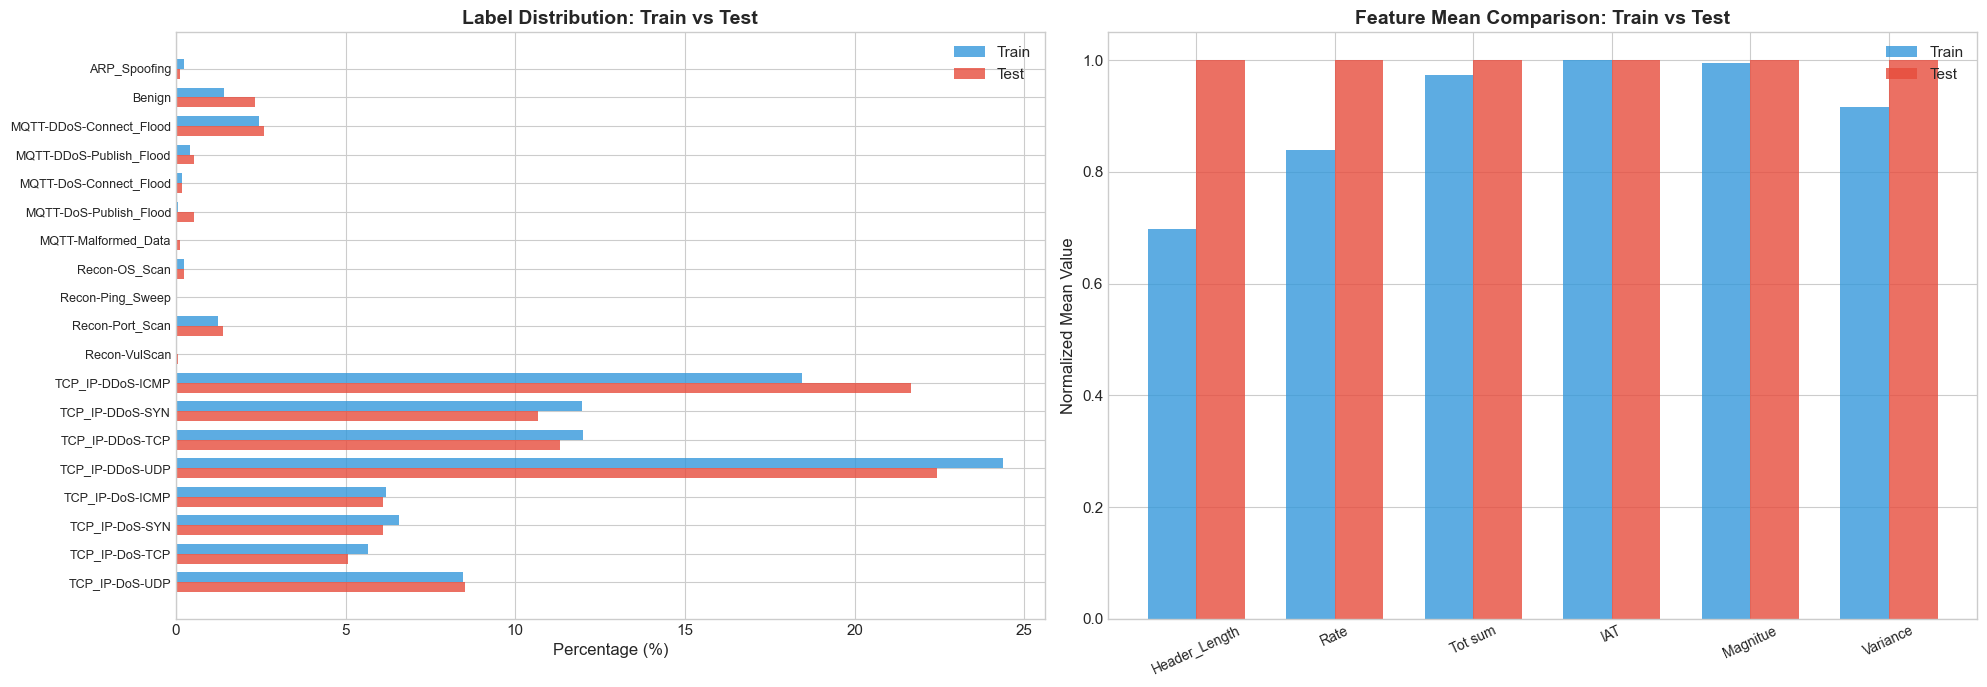

In [26]:
# ── Visual comparison of train/test distributions ──
fig, axes = plt.subplots(1, 2, figsize=(20, 7))

# Label distribution comparison
ax = axes[0]
x = np.arange(len(all_labels))
width = 0.35
ax.barh(x - width/2, train_pcts.values * 100, width, label='Train', color='#3498db', alpha=0.8)
ax.barh(x + width/2, test_pcts.values * 100, width, label='Test', color='#e74c3c', alpha=0.8)
ax.set_yticks(x)
ax.set_yticklabels(all_labels, fontsize=9)
ax.set_xlabel('Percentage (%)')
ax.set_title('Label Distribution: Train vs Test', fontweight='bold')
ax.legend()
ax.invert_yaxis()

# Feature distribution comparison (key features)
ax = axes[1]
compare_feats = ['Header_Length', 'Rate', 'Tot sum', 'IAT', 'Magnitue', 'Variance']
train_means = df_train[compare_feats].mean()
test_means = df_test[compare_feats].mean()

# Normalize for comparison
max_vals = pd.concat([train_means, test_means], axis=1).max(axis=1)
max_vals = max_vals.replace(0, 1)  # avoid division by zero
train_norm = train_means / max_vals
test_norm = test_means / max_vals

x2 = np.arange(len(compare_feats))
ax.bar(x2 - width/2, train_norm.values, width, label='Train', color='#3498db', alpha=0.8)
ax.bar(x2 + width/2, test_norm.values, width, label='Test', color='#e74c3c', alpha=0.8)
ax.set_xticks(x2)
ax.set_xticklabels(compare_feats, rotation=25, fontsize=10)
ax.set_ylabel('Normalized Mean Value')
ax.set_title('Feature Mean Comparison: Train vs Test', fontweight='bold')
ax.legend()

plt.tight_layout()
plt.show()

## 11. Data Quality Analysis

Data quality evaluation: zero-variance features, extreme values, class imbalance.

In [27]:
# ── Zero-variance and near-zero-variance features ──
print('Feature Variance Analysis')
print('=' * 60)

feature_variances = df[FEATURE_COLS].var().sort_values()
zero_var = feature_variances[feature_variances == 0]
near_zero_var = feature_variances[(feature_variances > 0) & (feature_variances < 0.001)]

if len(zero_var) > 0:
    print(f'\nZero-variance features ({len(zero_var)}):')
    for f, v in zero_var.items():
        print(f'  - {f}: constant value = {df[f].iloc[0]}')
else:
    print('No zero-variance features found.')

if len(near_zero_var) > 0:
    print(f'\nNear-zero-variance features (var < 0.001) ({len(near_zero_var)}):')
    for f, v in near_zero_var.items():
        print(f'  - {f}: var = {v:.6f}, unique values = {df[f].nunique()}')
else:
    print('No near-zero-variance features found.')

# ── Features with mostly zero values ──
print(f'\nFeatures with >90% Zero Values')
print('=' * 60)
for col in FEATURE_COLS:
    zero_pct = (df[col] == 0).mean() * 100
    if zero_pct > 90:
        print(f'  {col:25s}: {zero_pct:.1f}% zeros')

Feature Variance Analysis



Zero-variance features (1):
  - Drate: constant value = 0.0

Near-zero-variance features (var < 0.001) (13):
  - cwr_flag_number: var = 0.000000, unique values = 7
  - ece_flag_number: var = 0.000000, unique values = 8
  - Telnet: var = 0.000001, unique values = 6
  - SMTP: var = 0.000001, unique values = 7
  - IRC: var = 0.000001, unique values = 7


  - DHCP: var = 0.000001, unique values = 34
  - IGMP: var = 0.000001, unique values = 13
  - SSH: var = 0.000008, unique values = 17
  - DNS: var = 0.000021, unique values = 64
  - LLC: var = 0.000281, unique values = 85
  - IPv: var = 0.000281, unique values = 85


  - ARP: var = 0.000281, unique values = 85
  - HTTP: var = 0.000608, unique values = 34

Features with >90% Zero Values
  Drate                    : 100.0% zeros
  fin_flag_number          : 97.1% zeros
  psh_flag_number          : 93.8% zeros


  ece_flag_number          : 100.0% zeros
  cwr_flag_number          : 100.0% zeros
  ack_count                : 96.8% zeros
  HTTP                     : 99.8% zeros
  HTTPS                    : 97.3% zeros
  DNS                      : 99.8% zeros
  Telnet                   : 99.9% zeros
  SMTP                     : 99.9% zeros
  SSH                      : 99.9% zeros
  IRC                      : 99.9% zeros
  DHCP                     : 100.0% zeros
  ARP                      : 99.5% zeros
  IGMP                     : 100.0% zeros


Class Imbalance Analysis

Fine-grained (19 classes):
  Majority class: TCP_IP-DDoS-UDP (1,998,026)
  Minority class: Recon-Ping_Sweep (926)
  Imbalance ratio: 2157.7:1

Category-level (6 classes):
  Majority: DDoS (5,546,412)
  Minority: Spoofing (17,791)
  Imbalance ratio: 311.8:1



Binary (2 classes):
  Attack: 8,189,699 (98.4%)
  Benign: 133,197 (1.6%)
  Imbalance ratio: 61.49:1


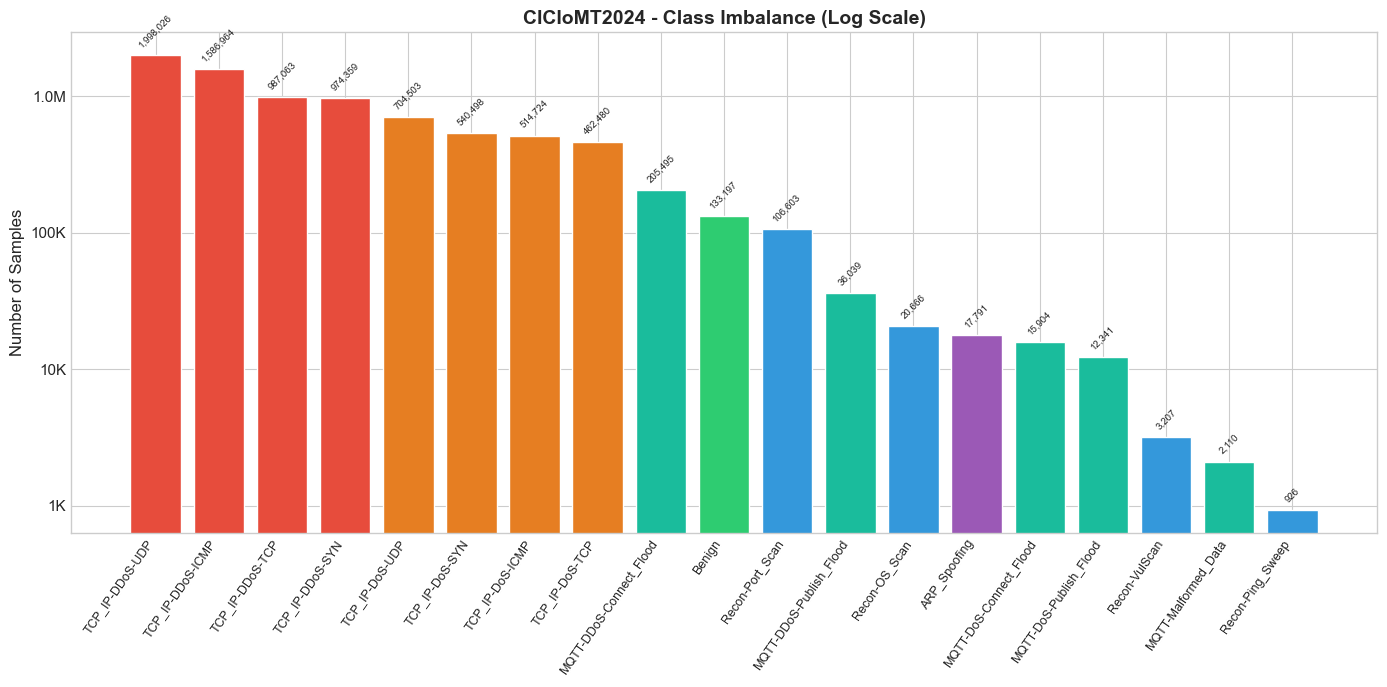

In [28]:
# ── Class Imbalance Analysis ──
print('Class Imbalance Analysis')
print('=' * 60)

label_counts_sorted = df['label'].value_counts()
n_majority = label_counts_sorted.iloc[0]
n_minority = label_counts_sorted.iloc[-1]

print(f'\nFine-grained (19 classes):')
print(f'  Majority class: {label_counts_sorted.index[0]} ({n_majority:,})')
print(f'  Minority class: {label_counts_sorted.index[-1]} ({n_minority:,})')
print(f'  Imbalance ratio: {n_majority / n_minority:.1f}:1')

cat_counts_sorted = df['attack_category'].value_counts()
print(f'\nCategory-level (6 classes):')
print(f'  Majority: {cat_counts_sorted.index[0]} ({cat_counts_sorted.iloc[0]:,})')
print(f'  Minority: {cat_counts_sorted.index[-1]} ({cat_counts_sorted.iloc[-1]:,})')
print(f'  Imbalance ratio: {cat_counts_sorted.iloc[0] / cat_counts_sorted.iloc[-1]:.1f}:1')

binary_counts_sorted = df['label'].apply(
    lambda x: 'Benign' if x == 'Benign' else 'Attack'
).value_counts()
print(f'\nBinary (2 classes):')
for lbl, cnt in binary_counts_sorted.items():
    print(f'  {lbl}: {cnt:,} ({cnt/len(df)*100:.1f}%)')
print(f'  Imbalance ratio: {binary_counts_sorted.iloc[0] / binary_counts_sorted.iloc[-1]:.2f}:1')

# ── Imbalance visualization ──
fig, ax = plt.subplots(figsize=(14, 7))
colors = [CATEGORY_COLORS.get(get_attack_category(l), '#95a5a6') for l in label_counts_sorted.index]

ax.bar(range(len(label_counts_sorted)), label_counts_sorted.values, color=colors, edgecolor='white')
ax.set_xticks(range(len(label_counts_sorted)))
ax.set_xticklabels(label_counts_sorted.index, rotation=55, ha='right', fontsize=9)
ax.set_ylabel('Number of Samples')
ax.set_yscale('log')
ax.set_title('CICIoMT2024 - Class Imbalance (Log Scale)', fontsize=14, fontweight='bold')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(
    lambda x, _: f'{x/1e6:.1f}M' if x >= 1e6 else f'{x/1e3:.0f}K' if x >= 1e3 else f'{x:.0f}'
))

# Add count labels
for i, (lbl, cnt) in enumerate(label_counts_sorted.items()):
    ax.text(i, cnt * 1.1, f'{cnt:,}', ha='center', va='bottom', fontsize=7, rotation=45)

plt.tight_layout()
plt.show()

In [29]:
# ── Feature value ranges and potential outliers ──
print('Feature Value Ranges & Potential Outlier Indicators')
print('=' * 80)
print(f'{"Feature":25s} {"Min":>12s} {"Max":>12s} {"Mean":>12s} {"Std":>12s} {"Skewness":>10s}')
print('-' * 85)

for col in FEATURE_COLS:
    series = df[col].replace([np.inf, -np.inf], np.nan).dropna()
    skew = series.skew()
    flag = ' ◄' if abs(skew) > 5 else ''
    print(f'{col:25s} {series.min():>12.2f} {series.max():>12.2f} '
          f'{series.mean():>12.2f} {series.std():>12.2f} {skew:>+10.2f}{flag}')

Feature Value Ranges & Potential Outlier Indicators
Feature                            Min          Max         Mean          Std   Skewness
-------------------------------------------------------------------------------------


Header_Length                     0.00   9896704.00     23903.02    233599.13     +24.27 ◄


Protocol Type                     0.00        17.00         8.33         6.32      +0.42
Duration                          0.00       255.00        64.51         6.40     +16.94 ◄
Rate                              0.00   2097152.00     15687.84     40088.30      +9.23 ◄


Srate                             0.00   2097152.00     15687.83     40088.29      +9.23 ◄


Drate                             0.00         0.00         0.00         0.00      +0.00
fin_flag_number                   0.00         1.00         0.01         0.03      +8.04 ◄
syn_flag_number                   0.00         1.00         0.17         0.34      +1.76


rst_flag_number                   0.00         1.00         0.04         0.14      +4.31


... (14 outputs left out)

Tot size                         42.00      1514.00        58.18        74.77     +13.97 ◄
IAT                              -1.28 169470846.24  84682792.32  15710003.33      -0.02
Number                            1.00        15.00         9.50         0.74      -0.05


Magnitue                          9.17        55.03        10.34         2.71     +10.84 ◄


Radius                            0.00      1014.27         6.93        48.34     +10.58 ◄
Covariance                        0.00    514420.17      1998.01     18220.36     +12.66 ◄
Variance                          0.00         1.00         0.08         0.22      +3.13


Weight                            1.00       244.60       141.53        19.10      -0.02


## 12. Summary & Key Findings

### Summary Findings

In [30]:
# ── Generate final summary ──
print('╔' + '═' * 68 + '╗')
print('║' + ' CICIoMT2024 Dataset - Summary Report'.center(68) + '║')
print('╠' + '═' * 68 + '╣')

print('║' + '  DATASET SIZE'.ljust(68) + '║')
print(f'║  Total samples:          {len(df):>10,}'.ljust(69) + '║')
print(f'║  Training samples:       {len(df_train):>10,} ({len(df_train)/len(df)*100:.1f}%)'.ljust(69) + '║')
print(f'║  Test samples:           {len(df_test):>10,} ({len(df_test)/len(df)*100:.1f}%)'.ljust(69) + '║')
print(f'║  Features:               {len(FEATURE_COLS):>10}'.ljust(69) + '║')
print(f'║  Memory usage:           {df.memory_usage(deep=True).sum()/1e9:.2f} GB'.ljust(69) + '║')

print('╠' + '═' * 68 + '╣')
print('║' + '  CLASSIFICATION LEVELS'.ljust(68) + '║')
print(f'║  Binary (Benign/Attack): 2 classes'.ljust(69) + '║')
print(f'║  Category-level:         {df["attack_category"].nunique()} classes'.ljust(69) + '║')
print(f'║  Fine-grained:           {df["label"].nunique()} classes (18 attacks + Benign)'.ljust(69) + '║')

print('╠' + '═' * 68 + '╣')
print('║' + '  ATTACK CATEGORIES'.ljust(68) + '║')
for cat in ordered_cats:
    cnt = (df['attack_category'] == cat).sum()
    pct = cnt / len(df) * 100
    n_sub = df[df['attack_category'] == cat]['label'].nunique()
    line = f'║  {cat:20s}: {cnt:>10,} ({pct:5.1f}%) - {n_sub} sub-types'
    print(line.ljust(69) + '║')

print('╠' + '═' * 68 + '╣')
print('║' + '  DATA QUALITY'.ljust(68) + '║')

null_total = df[FEATURE_COLS].isnull().sum().sum()
inf_total = np.isinf(df[FEATURE_COLS].select_dtypes(include=[np.number])).sum().sum()
dup_total = df[FEATURE_COLS].duplicated().sum()

print(f'║  Missing values:         {null_total:,}'.ljust(69) + '║')
print(f'║  Infinite values:        {inf_total:,}'.ljust(69) + '║')
print(f'║  Duplicate rows:         {dup_total:,} ({dup_total/len(df)*100:.1f}%)'.ljust(69) + '║')

print('╠' + '═' * 68 + '╣')
print('║' + '  KEY OBSERVATIONS'.ljust(68) + '║')
print('║  1. DDoS (TCP/IP) is the dominant attack category'.ljust(69) + '║')
print('║  2. Significant class imbalance (up to 2157:1)'.ljust(69) + '║')
print('║  3. ALL MQTT attacks in one category (paper Table 6)'.ljust(69) + '║')
print('║  4. MQTT attacks unique to this dataset (vs CICIoT2023)'.ljust(69) + '║')
print('║  5. Same 45 features as CICIoT2023 (DPKT extraction)'.ljust(69) + '║')
print('║  6. Duration column = TTL (not time duration)'.ljust(69) + '║')
print('║  7. Window aggregation: 10 or 100 packets per row'.ljust(69) + '║')
print('║  8. Partial dataset (missing profiling + BLE data)'.ljust(69) + '║')
print('╚' + '═' * 68 + '╝')

╔════════════════════════════════════════════════════════════════════╗
║                CICIoMT2024 Dataset - Summary Report                ║
╠════════════════════════════════════════════════════════════════════╣
║  DATASET SIZE                                                      ║
║  Total samples:           8,322,896                                ║
║  Training samples:        6,708,714 (80.6%)                        ║
║  Test samples:            1,614,182 (19.4%)                        ║
║  Features:                       45                                ║
║  Memory usage:           5.08 GB                                   ║
╠════════════════════════════════════════════════════════════════════╣
║  CLASSIFICATION LEVELS                                             ║
║  Binary (Benign/Attack): 2 classes                                 ║


║  Category-level:         6 classes                                 ║


║  Fine-grained:           19 classes (18 attacks + Benign)          ║
╠════════════════════════════════════════════════════════════════════╣
║  ATTACK CATEGORIES                                                 ║


║  Benign              :    133,197 (  1.6%) - 1 sub-types           ║


║  DDoS                :  5,546,412 ( 66.6%) - 4 sub-types           ║


║  DoS                 :  2,222,205 ( 26.7%) - 4 sub-types           ║
║  Reconnaissance      :    131,402 (  1.6%) - 4 sub-types           ║


║  Spoofing            :     17,791 (  0.2%) - 1 sub-types           ║


║  MQTT                :    271,889 (  3.3%) - 5 sub-types           ║
╠════════════════════════════════════════════════════════════════════╣
║  DATA QUALITY                                                      ║


║  Missing values:         148                                       ║
║  Infinite values:        0                                         ║
║  Duplicate rows:         7,216 (0.1%)                              ║
╠════════════════════════════════════════════════════════════════════╣
║  KEY OBSERVATIONS                                                  ║
║  1. DDoS (TCP/IP) is the dominant attack category                  ║
║  2. Significant class imbalance (up to 2157:1)                     ║
║  3. ALL MQTT attacks in one category (paper Table 6)               ║
║  4. MQTT attacks unique to this dataset (vs CICIoT2023)            ║
║  5. Same 45 features as CICIoT2023 (DPKT extraction)               ║
║  6. Duration column = TTL (not time duration)                      ║
║  7. Window aggregation: 10 or 100 packets per row                  ║
║  8. Partial dataset (missing profiling + BLE data)                 ║
╚════════════════════════════════════════════════════════════════════╝


### Important Observations for the Integration Pipeline

1. **Same Feature Schema**: CICIoMT2024 uses the same 45 features as CICIoT2023 (same DPKT extraction pipeline), which significantly facilitates merging.

2. **Unique MQTT Attacks**: The 5 MQTT-specific attacks (DDoS/DoS Connect & Publish Flood, Malformed Data) exist only in CICIoMT2024. These ALL belong to the "MQTT" category (paper Table 6).

3. **Class Imbalance**: The label distribution is highly imbalanced -- TCP/IP DDoS attacks dominate while MQTT-Malformed_Data and Recon-Ping_Sweep have very few samples. This requires sampling strategies.

4. **Train/Test Split**: ~80%/20% according to paper methodology (Section 5). The split is based on PCAP files, not random row sampling.

5. **High Correlation**: Some features exhibit very high correlation (|r| > 0.9), indicating redundancy. Feature selection will be useful.

6. **Duration = TTL**: The `Duration` column corresponds to Time-To-Live (values 0-255), not to time duration. This must be taken into account during feature engineering.

7. **Window-Based Aggregation**: Features are aggregated in windows of 10 or 100 packets (depending on the attack type). This means each row does not represent a single packet but a group of packets.

8. **Partial Dataset**: Our CSVs (WiFi+MQTT attacks) are a subset of the full dataset (~452K fewer samples vs Table 6). The difference is due to profiling benign traffic and some extra capture sessions -- it **does not affect** our analysis (IDS/ML classification).

9. **IoMT Context**: The dataset represents realistic scenarios on 40 medical IoT devices (blood pressure monitors, pulse oximeters, infusion pumps, thermometers etc.).